In [1]:
# =========================
# Module 0 — Imports & Setup
# =========================

import warnings
warnings.filterwarnings("ignore")

import os
import random
import numpy as np
import pandas as pd

from copy import deepcopy

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    f1_score,
    precision_score,
    recall_score,
    accuracy_score,
    matthews_corrcoef
)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import clone

from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Setup complete.")

# =========================
# Module 1 — Config
# =========================

DATA_PATH = "/kaggle/input/datasets/alexteboul/heart-disease-health-indicators-dataset/heart_disease_health_indicators_BRFSS2015.csv"   # <-- update this
TARGET_COL = "HeartDiseaseorAttack"                              # <-- update if needed

TEST_SIZE = 0.20
N_SPLITS = 5
USE_INTERACTIONS = True
USE_HARD_REWEIGHT = True
USE_TWO_STAGE = True

POS_LABEL = 1
NEG_LABEL = 0

print("Config loaded.")

# =========================
# Module 2 — Load Data
# =========================

df = pd.read_csv(DATA_PATH)
print("Data shape:", df.shape)
print(df.head())

assert TARGET_COL in df.columns, f"{TARGET_COL} not found in dataframe"

y = df[TARGET_COL].copy()
X = df.drop(columns=[TARGET_COL]).copy()

print("\nTarget distribution:")
print(y.value_counts(dropna=False))
print("\nTarget ratio:")
print(y.value_counts(normalize=True, dropna=False))

# =========================
# Module 3 — Basic Cleaning
# =========================

# Simple handling:
# - convert object/category columns using one-hot encoding
# - keep numeric as is

X = pd.get_dummies(X, drop_first=False)

# Ensure numeric only
for c in X.columns:
    X[c] = pd.to_numeric(X[c], errors="coerce")

# Very simple missing handling
X = X.fillna(X.median(numeric_only=True))

print("Processed feature shape:", X.shape)
print("Any missing left?", X.isna().sum().sum())

# =========================
# Module 4 — Feature Interactions
# =========================

def add_interaction_features(X_in: pd.DataFrame) -> pd.DataFrame:
    X_new = X_in.copy()
    
    candidate_pairs = [
        ("BMI", "Age"),
        ("BMI", "PhysicalHealth"),
        ("BMI", "Diabetic"),
        ("Smoking", "Age"),
        ("Stroke", "Age"),
        ("PhysicalHealth", "GenHealth"),
        ("MentalHealth", "GenHealth"),
        ("SleepTime", "Age"),
    ]
    
    # Try exact names first
    for a, b in candidate_pairs:
        if a in X_new.columns and b in X_new.columns:
            X_new[f"{a}_x_{b}"] = X_new[a] * X_new[b]
    
    # Optional broad matching for common BRFSS-like names
    def find_col(possible_keywords):
        for col in X_new.columns:
            col_low = col.lower()
            if all(k.lower() in col_low for k in possible_keywords):
                return col
        return None
    
    fuzzy_pairs = [
        (["bmi"], ["age"]),
        (["physical"], ["health"]),
        (["mental"], ["health"]),
        (["sleep"], ["time"]),
    ]
    
    # Example additional squared terms for important continuous features
    for keyword in [["bmi"], ["age"], ["physical"], ["mental"], ["sleep"]]:
        col = find_col(keyword)
        if col is not None and f"{col}_sq" not in X_new.columns:
            X_new[f"{col}_sq"] = X_new[col] ** 2
    
    return X_new

if USE_INTERACTIONS:
    X = add_interaction_features(X)

print("Feature shape after interactions:", X.shape)

# =========================
# Module 5 — Dev / Holdout Split
# =========================

X_dev, X_holdout, y_dev, y_holdout = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=SEED
)

print("Dev shape:", X_dev.shape, y_dev.shape)
print("Holdout shape:", X_holdout.shape, y_holdout.shape)

print("\nDev target ratio:")
print(y_dev.value_counts(normalize=True))

print("\nHoldout target ratio:")
print(y_holdout.value_counts(normalize=True))

# =========================
# Module 6 — Metrics Helpers
# =========================

def compute_metrics(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    
    out = {
        "PR_AUC": average_precision_score(y_true, y_prob),
        "ROC_AUC": roc_auc_score(y_true, y_prob),
        "Brier": brier_score_loss(y_true, y_prob),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "Accuracy": accuracy_score(y_true, y_pred),
        "MCC": matthews_corrcoef(y_true, y_pred),
    }
    return out

def summarize_cv_metrics(metrics_list, model_name):
    dfm = pd.DataFrame(metrics_list)
    summary = {"model": model_name}
    for c in dfm.columns:
        summary[f"{c}_mean"] = dfm[c].mean()
        summary[f"{c}_std"] = dfm[c].std()
    return summary

# =========================
# Module 7 — Model Definitions
# =========================

def get_models():
    models = {}
    
    models["logreg"] = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=SEED
        ))
    ])
    
    models["lgbm"] = LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        subsample=0.8,
        colsample_bytree=0.8,
        class_weight="balanced",
        random_state=SEED,
        verbosity=-1
    )
    
    models["xgb"] = XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=SEED,
        tree_method="hist"
    )
    
    models["catboost"] = CatBoostClassifier(
        iterations=300,
        learning_rate=0.05,
        depth=6,
        loss_function="Logloss",
        eval_metric="AUC",
        verbose=0,
        random_seed=SEED
    )
    
    return models

models = get_models()
print("Models:", list(models.keys()))

Setup complete.
Config loaded.
Data shape: (253680, 22)
   HeartDiseaseorAttack  HighBP  HighChol  CholCheck   BMI  Smoker  Stroke  \
0                   0.0     1.0       1.0        1.0  40.0     1.0     0.0   
1                   0.0     0.0       0.0        0.0  25.0     1.0     0.0   
2                   0.0     1.0       1.0        1.0  28.0     0.0     0.0   
3                   0.0     1.0       0.0        1.0  27.0     0.0     0.0   
4                   0.0     1.0       1.0        1.0  24.0     0.0     0.0   

   Diabetes  PhysActivity  Fruits  ...  AnyHealthcare  NoDocbcCost  GenHlth  \
0       0.0           0.0     0.0  ...            1.0          0.0      5.0   
1       0.0           1.0     0.0  ...            0.0          1.0      3.0   
2       0.0           0.0     1.0  ...            1.0          1.0      5.0   
3       0.0           1.0     1.0  ...            1.0          0.0      2.0   
4       0.0           1.0     1.0  ...            1.0          0.0      2.0   



In [5]:
# =========================
# Module 8 — CV Engine
# =========================

def fit_predict_model(model, X_tr, y_tr, X_va, sample_weight=None):
    model_local = clone(model)
    
    # Handle models that accept sample_weight at fit
    try:
        if sample_weight is not None:
            model_local.fit(X_tr, y_tr, clf__sample_weight=sample_weight)
        else:
            model_local.fit(X_tr, y_tr)
    except:
        try:
            if sample_weight is not None:
                model_local.fit(X_tr, y_tr, sample_weight=sample_weight)
            else:
                model_local.fit(X_tr, y_tr)
        except:
            model_local.fit(X_tr, y_tr)
    
    prob = model_local.predict_proba(X_va)[:, 1]
    return model_local, prob

def run_cv_oof(X_dev, y_dev, models, n_splits=5):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    
    all_oof = {}
    cv_summaries = []
    
    for model_name, model in models.items():
        oof_pred = np.zeros(len(X_dev), dtype=float)
        fold_metrics = []
        
        for fold, (tr_idx, va_idx) in enumerate(skf.split(X_dev, y_dev), start=1):
            X_tr = X_dev.iloc[tr_idx]
            y_tr = y_dev.iloc[tr_idx]
            X_va = X_dev.iloc[va_idx]
            y_va = y_dev.iloc[va_idx]
            
            fitted_model, va_prob = fit_predict_model(model, X_tr, y_tr, X_va)
            oof_pred[va_idx] = va_prob
            
            m = compute_metrics(y_va, va_prob)
            m["fold"] = fold
            fold_metrics.append(m)
        
        all_oof[model_name] = oof_pred
        cv_summaries.append(summarize_cv_metrics(fold_metrics, model_name))
    
    return all_oof, pd.DataFrame(cv_summaries)

oof_preds, cv_summary_df = run_cv_oof(X_dev, y_dev, models, n_splits=N_SPLITS)
cv_summary_df.sort_values("PR_AUC_mean", ascending=False)

,model,PR_AUC_mean,PR_AUC_std,ROC_AUC_mean,ROC_AUC_std,Brier_mean,Brier_std,F1_mean,F1_std,Precision_mean,Precision_std,Recall_mean,Recall_std,Accuracy_mean,Accuracy_std,MCC_mean,MCC_std,fold_mean,fold_std
3,catboost,0.377641,0.010297,0.850257,0.005323,0.069816,0.000670,0.169046,0.006325,0.570227,0.014281,0.099247,0.004100,0.908118,0.000475,0.210374,0.007074,3.0,1.581139
1,lgbm,0.376651,0.011124,0.848727,0.005619,0.161967,0.001157,0.371812,0.003716,0.241622,0.002188,0.806267,0.012464,0.743417,0.001859,0.341740,0.006277,3.0,1.581139
2,xgb,0.373582,0.010328,0.848622,0.005444,0.070090,0.000709,0.182172,0.002027,0.560502,0.015393,0.108768,0.001059,0.908019,0.000509,0.217813,0.004789,3.0,1.581139
0,logreg,0.371921,0.010669,0.847726,0.005584,0.165121,0.001450,0.375195,0.005370,0.245559,0.003480,0.794809,0.013134,0.750685,0.002530,0.343202,0.008154,3.0,1.581139


In [7]:
# =========================
# Module 9 — Baseline OOF Results
# =========================

baseline_dev_results = []

for model_name, oof_prob in oof_preds.items():
    row = {"model": model_name}
    row.update(compute_metrics(y_dev, oof_prob))
    baseline_dev_results.append(row)

baseline_dev_results_df = pd.DataFrame(baseline_dev_results).sort_values("PR_AUC", ascending=False)
baseline_dev_results_df

,model,PR_AUC,ROC_AUC,Brier,F1,Precision,Recall,Accuracy,MCC
3,catboost,0.377264,0.850244,0.069816,0.169066,0.570183,0.099247,0.908118,0.210391
1,lgbm,0.376235,0.848694,0.161967,0.371824,0.241627,0.806268,0.743417,0.341741
2,xgb,0.373166,0.848592,0.070090,0.182169,0.560226,0.108768,0.908019,0.217762
0,logreg,0.371572,0.847709,0.165121,0.375199,0.245559,0.794810,0.750685,0.343201


In [8]:
# =========================
# Module 10 — Hard Example Reweighting
# =========================

def make_hard_weights(y_true, base_prob, high_weight=3.0, base_weight=1.0):
    y_true = np.asarray(y_true)
    base_prob = np.asarray(base_prob)
    
    y_pred = (base_prob >= 0.5).astype(int)
    wrong = (y_pred != y_true).astype(int)
    
    # Emphasize false negatives more
    false_negative = ((y_true == 1) & (y_pred == 0)).astype(int)
    false_positive = ((y_true == 0) & (y_pred == 1)).astype(int)
    
    weights = np.ones_like(base_prob, dtype=float) * base_weight
    weights += wrong * (high_weight - 1.0)
    weights += false_negative * 1.0  # extra emphasis on FN
    
    return weights

def run_cv_oof_with_sample_weights(X_dev, y_dev, models, sample_weights, n_splits=5):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    
    all_oof = {}
    summary_rows = []
    
    for model_name, model in models.items():
        oof_pred = np.zeros(len(X_dev), dtype=float)
        fold_metrics = []
        
        for fold, (tr_idx, va_idx) in enumerate(skf.split(X_dev, y_dev), start=1):
            X_tr = X_dev.iloc[tr_idx]
            y_tr = y_dev.iloc[tr_idx]
            X_va = X_dev.iloc[va_idx]
            y_va = y_dev.iloc[va_idx]
            
            sw_tr = sample_weights[tr_idx]
            
            fitted_model, va_prob = fit_predict_model(model, X_tr, y_tr, X_va, sample_weight=sw_tr)
            oof_pred[va_idx] = va_prob
            
            m = compute_metrics(y_va, va_prob)
            m["fold"] = fold
            fold_metrics.append(m)
        
        all_oof[model_name] = oof_pred
        summary_rows.append(summarize_cv_metrics(fold_metrics, f"{model_name}_hardrw"))
    
    return all_oof, pd.DataFrame(summary_rows)

hardrw_dev_results_df = None
hardrw_oof_preds = {}

if USE_HARD_REWEIGHT:
    best_base_name = baseline_dev_results_df.iloc[0]["model"]
    best_base_oof = oof_preds[best_base_name]
    
    sample_weights = make_hard_weights(y_dev.values, best_base_oof, high_weight=3.0, base_weight=1.0)
    
    hardrw_oof_preds, hardrw_cv_summary_df = run_cv_oof_with_sample_weights(
        X_dev, y_dev, models, sample_weights, n_splits=N_SPLITS
    )
    
    hardrw_rows = []
    for model_name, prob in hardrw_oof_preds.items():
        row = {"model": f"{model_name}_hardrw"}
        row.update(compute_metrics(y_dev, prob))
        hardrw_rows.append(row)
    
    hardrw_dev_results_df = pd.DataFrame(hardrw_rows).sort_values("PR_AUC", ascending=False)
    print("Best baseline for hard reweighting seed:", best_base_name)
    display(hardrw_dev_results_df)

Best baseline for hard reweighting seed: catboost


,model,PR_AUC,ROC_AUC,Brier,F1,Precision,Recall,Accuracy,MCC
0,logreg_hardrw,0.364654,0.846513,0.337561,0.265328,0.153860,0.963011,0.497719,0.244836
1,lgbm_hardrw,0.319618,0.841100,0.316412,0.281784,0.165523,0.946793,0.545431,0.263956
3,catboost_hardrw,0.311085,0.841890,0.098293,0.401380,0.319898,0.538558,0.848702,0.335458
2,xgb_hardrw,0.304480,0.838844,0.097767,0.397160,0.317704,0.529612,0.848574,0.330257


In [10]:
# =========================
# Module 11 — Two-Stage Model
# =========================

def run_two_stage_oof(
    X_dev, y_dev,
    stage1_model,
    stage2_model,
    n_splits=5,
    low_thr=0.20,
    high_thr=0.80
):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    oof_final = np.zeros(len(X_dev), dtype=float)
    
    for fold, (tr_idx, va_idx) in enumerate(skf.split(X_dev, y_dev), start=1):
        X_tr = X_dev.iloc[tr_idx]
        y_tr = y_dev.iloc[tr_idx]
        X_va = X_dev.iloc[va_idx]
        
        m1 = clone(stage1_model)
        m1.fit(X_tr, y_tr)
        
        tr_prob_stage1 = m1.predict_proba(X_tr)[:, 1]
        va_prob_stage1 = m1.predict_proba(X_va)[:, 1]
        
        # ambiguous region in training data
        ambiguous_mask_tr = (tr_prob_stage1 >= low_thr) & (tr_prob_stage1 <= high_thr)
        
        # fallback: if too few ambiguous samples, take all
        if ambiguous_mask_tr.sum() < 100:
            ambiguous_mask_tr = np.ones(len(X_tr), dtype=bool)
        
        X_tr_stage2 = X_tr.iloc[ambiguous_mask_tr]
        y_tr_stage2 = y_tr.iloc[ambiguous_mask_tr]
        
        m2 = clone(stage2_model)
        m2.fit(X_tr_stage2, y_tr_stage2)
        
        ambiguous_mask_va = (va_prob_stage1 >= low_thr) & (va_prob_stage1 <= high_thr)
        final_prob = va_prob_stage1.copy()
        
        if ambiguous_mask_va.sum() > 0:
            va_prob_stage2 = m2.predict_proba(X_va.iloc[ambiguous_mask_va])[:, 1]
            # simple blend
            final_prob[ambiguous_mask_va] = 0.5 * va_prob_stage1[ambiguous_mask_va] + 0.5 * va_prob_stage2
        
        oof_final[va_idx] = final_prob
    
    return oof_final

two_stage_results_df = None
two_stage_oof = None

if USE_TWO_STAGE:
    stage1 = clone(models["catboost"])
    stage2 = clone(models["lgbm"])
    
    two_stage_oof = run_two_stage_oof(
        X_dev, y_dev,
        stage1_model=stage1,
        stage2_model=stage2,
        n_splits=N_SPLITS,
        low_thr=0.20,
        high_thr=0.80
    )
    
    two_stage_row = {"model": "two_stage_catboost_lgbm"}
    two_stage_row.update(compute_metrics(y_dev, two_stage_oof))
    two_stage_results_df = pd.DataFrame([two_stage_row]).sort_values("PR_AUC", ascending=False)
    two_stage_results_df

In [11]:
# =========================
# Module 12 — Compare Dev Results
# =========================

all_dev_tables = [baseline_dev_results_df]

if hardrw_dev_results_df is not None:
    all_dev_tables.append(hardrw_dev_results_df)

if two_stage_results_df is not None:
    all_dev_tables.append(two_stage_results_df)

dev_compare_df = pd.concat(all_dev_tables, axis=0, ignore_index=True)
dev_compare_df = dev_compare_df.sort_values(["PR_AUC", "ROC_AUC"], ascending=False).reset_index(drop=True)
dev_compare_df

,model,PR_AUC,ROC_AUC,Brier,F1,Precision,Recall,Accuracy,MCC
0,catboost,0.377264,0.850244,0.069816,0.169066,0.570183,0.099247,0.908118,0.210391
1,lgbm,0.376235,0.848694,0.161967,0.371824,0.241627,0.806268,0.743417,0.341741
2,two_stage_catboost_lgbm,0.376165,0.849974,0.070798,0.252001,0.519268,0.166370,0.906979,0.256715
3,xgb,0.373166,0.848592,0.070090,0.182169,0.560226,0.108768,0.908019,0.217762
4,logreg,0.371572,0.847709,0.165121,0.375199,0.245559,0.794810,0.750685,0.343201
5,logreg_hardrw,0.364654,0.846513,0.337561,0.265328,0.153860,0.963011,0.497719,0.244836
6,lgbm_hardrw,0.319618,0.841100,0.316412,0.281784,0.165523,0.946793,0.545431,0.263956
7,catboost_hardrw,0.311085,0.841890,0.098293,0.401380,0.319898,0.538558,0.848702,0.335458
8,xgb_hardrw,0.304480,0.838844,0.097767,0.397160,0.317704,0.529612,0.848574,0.330257


In [12]:
# =========================
# Module 13 — Holdout Evaluation
# =========================

def fit_full_and_predict(model, X_tr, y_tr, X_te, sample_weight=None):
    model_local = clone(model)
    try:
        if sample_weight is not None:
            model_local.fit(X_tr, y_tr, clf__sample_weight=sample_weight)
        else:
            model_local.fit(X_tr, y_tr)
    except:
        try:
            if sample_weight is not None:
                model_local.fit(X_tr, y_tr, sample_weight=sample_weight)
            else:
                model_local.fit(X_tr, y_tr)
        except:
            model_local.fit(X_tr, y_tr)
    return model_local.predict_proba(X_te)[:, 1], model_local

holdout_rows = []

# Baselines
for model_name, model in models.items():
    hold_prob, _ = fit_full_and_predict(model, X_dev, y_dev, X_holdout)
    row = {"model": model_name}
    row.update(compute_metrics(y_holdout, hold_prob))
    holdout_rows.append(row)

# Hard-reweighted best baseline
if USE_HARD_REWEIGHT:
    best_base_name = baseline_dev_results_df.iloc[0]["model"]
    sw_full = make_hard_weights(y_dev.values, oof_preds[best_base_name], high_weight=3.0, base_weight=1.0)
    
    for model_name, model in models.items():
        hold_prob, _ = fit_full_and_predict(model, X_dev, y_dev, X_holdout, sample_weight=sw_full)
        row = {"model": f"{model_name}_hardrw"}
        row.update(compute_metrics(y_holdout, hold_prob))
        holdout_rows.append(row)

# Two-stage
if USE_TWO_STAGE:
    stage1 = clone(models["catboost"])
    stage2 = clone(models["lgbm"])
    
    stage1.fit(X_dev, y_dev)
    dev_stage1_prob = stage1.predict_proba(X_dev)[:, 1]
    hold_stage1_prob = stage1.predict_proba(X_holdout)[:, 1]
    
    ambiguous_dev = (dev_stage1_prob >= 0.20) & (dev_stage1_prob <= 0.80)
    if ambiguous_dev.sum() < 100:
        ambiguous_dev = np.ones(len(X_dev), dtype=bool)
    
    stage2.fit(X_dev.iloc[ambiguous_dev], y_dev.iloc[ambiguous_dev])
    
    ambiguous_hold = (hold_stage1_prob >= 0.20) & (hold_stage1_prob <= 0.80)
    final_hold_prob = hold_stage1_prob.copy()
    
    if ambiguous_hold.sum() > 0:
        hold_stage2_prob = stage2.predict_proba(X_holdout.iloc[ambiguous_hold])[:, 1]
        final_hold_prob[ambiguous_hold] = 0.5 * hold_stage1_prob[ambiguous_hold] + 0.5 * hold_stage2_prob
    
    row = {"model": "two_stage_catboost_lgbm"}
    row.update(compute_metrics(y_holdout, final_hold_prob))
    holdout_rows.append(row)

holdout_results_df = pd.DataFrame(holdout_rows).sort_values(["PR_AUC", "ROC_AUC"], ascending=False).reset_index(drop=True)
holdout_results_df

,model,PR_AUC,ROC_AUC,Brier,F1,Precision,Recall,Accuracy,MCC
0,catboost,0.372823,0.850884,0.069928,0.163542,0.557178,0.095836,0.907659,0.203406
1,two_stage_catboost_lgbm,0.370366,0.850495,0.070876,0.250828,0.509615,0.166353,0.906398,0.253307
2,lgbm,0.369758,0.850015,0.161933,0.374271,0.243170,0.812095,0.744225,0.345516
3,xgb,0.367522,0.849988,0.070173,0.170040,0.535477,0.101067,0.907068,0.203250
4,logreg,0.363813,0.847522,0.164494,0.378822,0.248072,0.801004,0.752562,0.348280
5,logreg_hardrw,0.357375,0.846393,0.336468,0.265030,0.153789,0.957941,0.499547,0.243100
6,lgbm_hardrw,0.326125,0.844274,0.319118,0.280364,0.164517,0.947688,0.541746,0.262217
7,catboost_hardrw,0.321229,0.844455,0.097653,0.411213,0.328018,0.550952,0.851388,0.347039
8,xgb_hardrw,0.313984,0.842734,0.097178,0.408230,0.325261,0.548023,0.850343,0.343581


In [13]:
# =========================
# Module 14 — Quick Interpretation
# =========================

print("Best DEV model:")
display(dev_compare_df.head(5))

print("\nBest HOLDOUT model:")
display(holdout_results_df.head(10))

Best DEV model:


,model,PR_AUC,ROC_AUC,Brier,F1,Precision,Recall,Accuracy,MCC
0,catboost,0.377264,0.850244,0.069816,0.169066,0.570183,0.099247,0.908118,0.210391
1,lgbm,0.376235,0.848694,0.161967,0.371824,0.241627,0.806268,0.743417,0.341741
2,two_stage_catboost_lgbm,0.376165,0.849974,0.070798,0.252001,0.519268,0.166370,0.906979,0.256715
3,xgb,0.373166,0.848592,0.070090,0.182169,0.560226,0.108768,0.908019,0.217762
4,logreg,0.371572,0.847709,0.165121,0.375199,0.245559,0.794810,0.750685,0.343201



Best HOLDOUT model:


,model,PR_AUC,ROC_AUC,Brier,F1,Precision,Recall,Accuracy,MCC
0,catboost,0.372823,0.850884,0.069928,0.163542,0.557178,0.095836,0.907659,0.203406
1,two_stage_catboost_lgbm,0.370366,0.850495,0.070876,0.250828,0.509615,0.166353,0.906398,0.253307
2,lgbm,0.369758,0.850015,0.161933,0.374271,0.243170,0.812095,0.744225,0.345516
3,xgb,0.367522,0.849988,0.070173,0.170040,0.535477,0.101067,0.907068,0.203250
4,logreg,0.363813,0.847522,0.164494,0.378822,0.248072,0.801004,0.752562,0.348280
5,logreg_hardrw,0.357375,0.846393,0.336468,0.265030,0.153789,0.957941,0.499547,0.243100
6,lgbm_hardrw,0.326125,0.844274,0.319118,0.280364,0.164517,0.947688,0.541746,0.262217
7,catboost_hardrw,0.321229,0.844455,0.097653,0.411213,0.328018,0.550952,0.851388,0.347039
8,xgb_hardrw,0.313984,0.842734,0.097178,0.408230,0.325261,0.548023,0.850343,0.343581


In [14]:
# =========================
# Module 15 — Meta Features from OOF Predictions
# =========================

base_models_for_stack = ["catboost", "lgbm", "xgb"]

meta_X_dev = pd.DataFrame({
    f"{m}_prob": oof_preds[m] for m in base_models_for_stack
}, index=X_dev.index)

# simple agreement / uncertainty features
meta_X_dev["prob_mean"] = meta_X_dev.mean(axis=1)
meta_X_dev["prob_std"]  = meta_X_dev.std(axis=1)
meta_X_dev["prob_max"]  = meta_X_dev.max(axis=1)
meta_X_dev["prob_min"]  = meta_X_dev.min(axis=1)
meta_X_dev["prob_range"] = meta_X_dev["prob_max"] - meta_X_dev["prob_min"]

meta_y_dev = y_dev.values.copy()

print("meta_X_dev shape:", meta_X_dev.shape)
meta_X_dev.head()

# =========================
# Module 16 — Train Meta-Learner on OOF Meta Features
# =========================

from sklearn.linear_model import LogisticRegression

stacker = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=SEED
)

stacker.fit(meta_X_dev, meta_y_dev)
stack_dev_prob = stacker.predict_proba(meta_X_dev)[:, 1]

stack_dev_row = {"model": "stack_logreg"}
stack_dev_row.update(compute_metrics(meta_y_dev, stack_dev_prob))

stack_dev_results_df = pd.DataFrame([stack_dev_row]).sort_values("PR_AUC", ascending=False)
stack_dev_results_df

# =========================
# Module 17 — Full-Dev Base Models for Holdout Stacking
# =========================

fitted_base_models = {}
holdout_base_probs = {}

for model_name in base_models_for_stack:
    model = clone(models[model_name])
    model.fit(X_dev, y_dev)
    fitted_base_models[model_name] = model
    holdout_base_probs[model_name] = model.predict_proba(X_holdout)[:, 1]

meta_X_holdout = pd.DataFrame({
    f"{m}_prob": holdout_base_probs[m] for m in base_models_for_stack
}, index=X_holdout.index)

meta_X_holdout["prob_mean"] = meta_X_holdout.mean(axis=1)
meta_X_holdout["prob_std"]  = meta_X_holdout.std(axis=1)
meta_X_holdout["prob_max"]  = meta_X_holdout.max(axis=1)
meta_X_holdout["prob_min"]  = meta_X_holdout.min(axis=1)
meta_X_holdout["prob_range"] = meta_X_holdout["prob_max"] - meta_X_holdout["prob_min"]

print("meta_X_holdout shape:", meta_X_holdout.shape)
meta_X_holdout.head()

# =========================
# Module 18 — Holdout Evaluation of Stacking Model
# =========================

stack_holdout_prob = stacker.predict_proba(meta_X_holdout)[:, 1]

stack_holdout_row = {"model": "stack_logreg"}
stack_holdout_row.update(compute_metrics(y_holdout, stack_holdout_prob))

stack_holdout_results_df = pd.DataFrame([stack_holdout_row]).sort_values("PR_AUC", ascending=False)
stack_holdout_results_df

# =========================
# Module 19 — Compare With Existing Results
# =========================

dev_compare_with_stack_df = pd.concat(
    [dev_compare_df, stack_dev_results_df],
    axis=0,
    ignore_index=True
).sort_values(["PR_AUC", "ROC_AUC"], ascending=False).reset_index(drop=True)

holdout_compare_with_stack_df = pd.concat(
    [holdout_results_df, stack_holdout_results_df],
    axis=0,
    ignore_index=True
).sort_values(["PR_AUC", "ROC_AUC"], ascending=False).reset_index(drop=True)

print("Best DEV model:")
display(dev_compare_with_stack_df.head(10))

print("\nBest HOLDOUT model:")
display(holdout_compare_with_stack_df.head(10))

# =========================
# Module 20 — Optional CatBoost Stacker
# =========================

stacker_cb = CatBoostClassifier(
    iterations=200,
    learning_rate=0.05,
    depth=4,
    loss_function="Logloss",
    eval_metric="AUC",
    verbose=0,
    random_seed=SEED
)

stacker_cb.fit(meta_X_dev, meta_y_dev)

stack_cb_dev_prob = stacker_cb.predict_proba(meta_X_dev)[:, 1]
stack_cb_holdout_prob = stacker_cb.predict_proba(meta_X_holdout)[:, 1]

stack_cb_dev_row = {"model": "stack_catboost"}
stack_cb_dev_row.update(compute_metrics(meta_y_dev, stack_cb_dev_prob))

stack_cb_holdout_row = {"model": "stack_catboost"}
stack_cb_holdout_row.update(compute_metrics(y_holdout, stack_cb_holdout_prob))

stack_cb_dev_results_df = pd.DataFrame([stack_cb_dev_row])
stack_cb_holdout_results_df = pd.DataFrame([stack_cb_holdout_row])

dev_compare_with_stack_df = pd.concat(
    [dev_compare_with_stack_df, stack_cb_dev_results_df],
    axis=0,
    ignore_index=True
).sort_values(["PR_AUC", "ROC_AUC"], ascending=False).reset_index(drop=True)

holdout_compare_with_stack_df = pd.concat(
    [holdout_compare_with_stack_df, stack_cb_holdout_results_df],
    axis=0,
    ignore_index=True
).sort_values(["PR_AUC", "ROC_AUC"], ascending=False).reset_index(drop=True)

print("Updated DEV comparison:")
display(dev_compare_with_stack_df.head(12))

print("\nUpdated HOLDOUT comparison:")
display(holdout_compare_with_stack_df.head(12))

meta_X_dev shape: (202944, 8)
meta_X_holdout shape: (50736, 8)
Best DEV model:


,model,PR_AUC,ROC_AUC,Brier,F1,Precision,Recall,Accuracy,MCC
0,catboost,0.377264,0.850244,0.069816,0.169066,0.570183,0.099247,0.908118,0.210391
1,lgbm,0.376235,0.848694,0.161967,0.371824,0.241627,0.806268,0.743417,0.341741
2,stack_logreg,0.376193,0.848423,0.165734,0.368829,0.238535,0.812807,0.737992,0.339751
3,two_stage_catboost_lgbm,0.376165,0.849974,0.070798,0.252001,0.519268,0.166370,0.906979,0.256715
4,xgb,0.373166,0.848592,0.070090,0.182169,0.560226,0.108768,0.908019,0.217762
5,logreg,0.371572,0.847709,0.165121,0.375199,0.245559,0.794810,0.750685,0.343201
6,logreg_hardrw,0.364654,0.846513,0.337561,0.265328,0.153860,0.963011,0.497719,0.244836
7,lgbm_hardrw,0.319618,0.841100,0.316412,0.281784,0.165523,0.946793,0.545431,0.263956
8,catboost_hardrw,0.311085,0.841890,0.098293,0.401380,0.319898,0.538558,0.848702,0.335458
9,xgb_hardrw,0.304480,0.838844,0.097767,0.397160,0.317704,0.529612,0.848574,0.330257



Best HOLDOUT model:


,model,PR_AUC,ROC_AUC,Brier,F1,Precision,Recall,Accuracy,MCC
0,catboost,0.372823,0.850884,0.069928,0.163542,0.557178,0.095836,0.907659,0.203406
1,stack_logreg,0.371040,0.849709,0.165454,0.371273,0.240010,0.819418,0.738588,0.343700
2,two_stage_catboost_lgbm,0.370366,0.850495,0.070876,0.250828,0.509615,0.166353,0.906398,0.253307
3,lgbm,0.369758,0.850015,0.161933,0.374271,0.243170,0.812095,0.744225,0.345516
4,xgb,0.367522,0.849988,0.070173,0.170040,0.535477,0.101067,0.907068,0.203250
5,logreg,0.363813,0.847522,0.164494,0.378822,0.248072,0.801004,0.752562,0.348280
6,logreg_hardrw,0.357375,0.846393,0.336468,0.265030,0.153789,0.957941,0.499547,0.243100
7,lgbm_hardrw,0.326125,0.844274,0.319118,0.280364,0.164517,0.947688,0.541746,0.262217
8,catboost_hardrw,0.321229,0.844455,0.097653,0.411213,0.328018,0.550952,0.851388,0.347039
9,xgb_hardrw,0.313984,0.842734,0.097178,0.408230,0.325261,0.548023,0.850343,0.343581


Updated DEV comparison:


,model,PR_AUC,ROC_AUC,Brier,F1,Precision,Recall,Accuracy,MCC
0,stack_catboost,0.380267,0.850773,0.069670,0.144179,0.600230,0.081929,0.908393,0.197716
1,catboost,0.377264,0.850244,0.069816,0.169066,0.570183,0.099247,0.908118,0.210391
2,lgbm,0.376235,0.848694,0.161967,0.371824,0.241627,0.806268,0.743417,0.341741
3,stack_logreg,0.376193,0.848423,0.165734,0.368829,0.238535,0.812807,0.737992,0.339751
4,two_stage_catboost_lgbm,0.376165,0.849974,0.070798,0.252001,0.519268,0.166370,0.906979,0.256715
5,xgb,0.373166,0.848592,0.070090,0.182169,0.560226,0.108768,0.908019,0.217762
6,logreg,0.371572,0.847709,0.165121,0.375199,0.245559,0.794810,0.750685,0.343201
7,logreg_hardrw,0.364654,0.846513,0.337561,0.265328,0.153860,0.963011,0.497719,0.244836
8,lgbm_hardrw,0.319618,0.841100,0.316412,0.281784,0.165523,0.946793,0.545431,0.263956
9,catboost_hardrw,0.311085,0.841890,0.098293,0.401380,0.319898,0.538558,0.848702,0.335458



Updated HOLDOUT comparison:


,model,PR_AUC,ROC_AUC,Brier,F1,Precision,Recall,Accuracy,MCC
0,catboost,0.372823,0.850884,0.069928,0.163542,0.557178,0.095836,0.907659,0.203406
1,stack_catboost,0.371469,0.850987,0.069958,0.139032,0.563150,0.079305,0.907482,0.186146
2,stack_logreg,0.371040,0.849709,0.165454,0.371273,0.240010,0.819418,0.738588,0.343700
3,two_stage_catboost_lgbm,0.370366,0.850495,0.070876,0.250828,0.509615,0.166353,0.906398,0.253307
4,lgbm,0.369758,0.850015,0.161933,0.374271,0.243170,0.812095,0.744225,0.345516
5,xgb,0.367522,0.849988,0.070173,0.170040,0.535477,0.101067,0.907068,0.203250
6,logreg,0.363813,0.847522,0.164494,0.378822,0.248072,0.801004,0.752562,0.348280
7,logreg_hardrw,0.357375,0.846393,0.336468,0.265030,0.153789,0.957941,0.499547,0.243100
8,lgbm_hardrw,0.326125,0.844274,0.319118,0.280364,0.164517,0.947688,0.541746,0.262217
9,catboost_hardrw,0.321229,0.844455,0.097653,0.411213,0.328018,0.550952,0.851388,0.347039


In [17]:
# =========================
# Module M0 — PyTorch imports
# =========================

import copy
import math
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("DEVICE:", DEVICE)
# =========================
# Module M1 — Prepare arrays
# =========================

X_dev_moe = X_dev.copy()
X_holdout_moe = X_holdout.copy()

# MoE usually benefits from scaling
scaler_moe = StandardScaler()
X_dev_moe_scaled = scaler_moe.fit_transform(X_dev_moe).astype(np.float32)
X_holdout_moe_scaled = scaler_moe.transform(X_holdout_moe).astype(np.float32)

y_dev_moe = y_dev.values.astype(np.float32)
y_holdout_moe = y_holdout.values.astype(np.float32)

print(X_dev_moe_scaled.shape, y_dev_moe.shape)
print(X_holdout_moe_scaled.shape, y_holdout_moe.shape)
# =========================
# Module M2 — Dataset
# =========================

class TabularDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# =========================
# Module M3 — Simple MoE model
# =========================

class ExpertMLP(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.BatchNorm1d(hidden_dim),
            nn.Dropout(dropout),

            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.BatchNorm1d(hidden_dim),
            nn.Dropout(dropout),

            nn.Linear(hidden_dim, 1)
        )

    def forward(self, x):
        return self.net(x)  # logits


class GatingNet(nn.Module):
    def __init__(self, input_dim, n_experts=3, hidden_dim=32, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.BatchNorm1d(hidden_dim),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, n_experts)
        )

    def forward(self, x):
        return self.net(x)  # raw gate logits


class SimpleMoE(nn.Module):
    def __init__(self, input_dim, n_experts=3, expert_hidden=64, gate_hidden=32, dropout=0.2):
        super().__init__()
        self.n_experts = n_experts
        self.experts = nn.ModuleList([
            ExpertMLP(input_dim=input_dim, hidden_dim=expert_hidden, dropout=dropout)
            for _ in range(n_experts)
        ])
        self.gate = GatingNet(
            input_dim=input_dim,
            n_experts=n_experts,
            hidden_dim=gate_hidden,
            dropout=dropout / 2
        )

    def forward(self, x):
        # expert logits: [B, n_experts]
        expert_logits = torch.cat([expert(x) for expert in self.experts], dim=1)

        # gate weights: [B, n_experts]
        gate_logits = self.gate(x)
        gate_weights = torch.softmax(gate_logits, dim=1)

        # weighted sum of logits
        final_logit = (expert_logits * gate_weights).sum(dim=1, keepdim=True)

        return {
            "logit": final_logit.squeeze(1),
            "expert_logits": expert_logits,
            "gate_weights": gate_weights
        }

# =========================
# Module M4 — Helpers
# =========================

def compute_binary_metrics_np(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    return {
        "PR_AUC": average_precision_score(y_true, y_prob),
        "ROC_AUC": roc_auc_score(y_true, y_prob),
        "Brier": brier_score_loss(y_true, y_prob),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "Accuracy": accuracy_score(y_true, y_pred),
        "MCC": matthews_corrcoef(y_true, y_pred),
    }


@torch.no_grad()
def predict_proba_moe(model, loader, device="cuda"):
    model.eval()
    probs = []

    for xb, _ in loader:
        xb = xb.to(device)
        out = model(xb)
        prob = torch.sigmoid(out["logit"]).detach().cpu().numpy()
        probs.append(prob)

    return np.concatenate(probs)


def train_one_fold_moe(
    X_tr, y_tr, X_va, y_va,
    input_dim,
    n_experts=3,
    expert_hidden=64,
    gate_hidden=32,
    dropout=0.2,
    lr=1e-3,
    weight_decay=1e-5,
    batch_size=1024,
    max_epochs=30,
    patience=5,
    device="cuda"
):
    train_ds = TabularDataset(X_tr, y_tr)
    valid_ds = TabularDataset(X_va, y_va)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, drop_last=False)
    valid_loader = DataLoader(valid_ds, batch_size=batch_size, shuffle=False, drop_last=False)

    model = SimpleMoE(
        input_dim=input_dim,
        n_experts=n_experts,
        expert_hidden=expert_hidden,
        gate_hidden=gate_hidden,
        dropout=dropout
    ).to(device)

    pos_count = max(1.0, float((y_tr == 1).sum()))
    neg_count = max(1.0, float((y_tr == 0).sum()))
    pos_weight = torch.tensor([neg_count / pos_count], dtype=torch.float32, device=device)

    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    best_score = -np.inf
    best_state = None
    best_epoch = 0
    wait = 0

    for epoch in range(1, max_epochs + 1):
        model.train()
        train_losses = []

        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()
            out = model(xb)

            loss_main = criterion(out["logit"], yb)

            # mild load-balancing regularizer on mean gate usage
            gate_mean = out["gate_weights"].mean(dim=0)
            uniform = torch.full_like(gate_mean, 1.0 / gate_mean.numel())
            loss_balance = ((gate_mean - uniform) ** 2).mean()

            loss = loss_main + 0.01 * loss_balance
            loss.backward()
            optimizer.step()

            train_losses.append(loss.item())

        va_prob = predict_proba_moe(model, valid_loader, device=device)
        va_pr_auc = average_precision_score(y_va, va_prob)

        print(
            f"Epoch {epoch:02d} | "
            f"train_loss={np.mean(train_losses):.5f} | "
            f"val_PR_AUC={va_pr_auc:.6f}"
        )

        if va_pr_auc > best_score:
            best_score = va_pr_auc
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print(f"Early stopping at epoch {epoch}, best epoch {best_epoch}, best PR_AUC={best_score:.6f}")
                break

    model.load_state_dict(best_state)
    va_prob = predict_proba_moe(model, valid_loader, device=device)

    return model, va_prob, best_score, best_epoch

# =========================
# Module M5 — CV OOF for MoE
# =========================

def run_moe_cv_oof(
    X_dev_np,
    y_dev_np,
    n_splits=5,
    seed=42,
    n_experts=3,
    expert_hidden=64,
    gate_hidden=32,
    dropout=0.2,
    lr=1e-3,
    weight_decay=1e-5,
    batch_size=1024,
    max_epochs=30,
    patience=5,
    device="cuda"
):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)

    oof_pred = np.zeros(len(X_dev_np), dtype=np.float32)
    fold_metrics = []
    fold_models = []

    for fold, (tr_idx, va_idx) in enumerate(skf.split(X_dev_np, y_dev_np), start=1):
        print(f"\n========== Fold {fold}/{n_splits} ==========")

        X_tr = X_dev_np[tr_idx]
        y_tr = y_dev_np[tr_idx]
        X_va = X_dev_np[va_idx]
        y_va = y_dev_np[va_idx]

        model, va_prob, best_score, best_epoch = train_one_fold_moe(
            X_tr, y_tr, X_va, y_va,
            input_dim=X_dev_np.shape[1],
            n_experts=n_experts,
            expert_hidden=expert_hidden,
            gate_hidden=gate_hidden,
            dropout=dropout,
            lr=lr,
            weight_decay=weight_decay,
            batch_size=batch_size,
            max_epochs=max_epochs,
            patience=patience,
            device=device
        )

        oof_pred[va_idx] = va_prob
        fold_models.append(model)

        m = compute_binary_metrics_np(y_va, va_prob)
        m["fold"] = fold
        m["best_epoch"] = best_epoch
        m["best_pr_auc"] = best_score
        fold_metrics.append(m)

        print("Fold metrics:", m)

    fold_df = pd.DataFrame(fold_metrics)

    summary = {
        "model": "simple_moe",
        "PR_AUC_mean": fold_df["PR_AUC"].mean(),
        "PR_AUC_std": fold_df["PR_AUC"].std(),
        "ROC_AUC_mean": fold_df["ROC_AUC"].mean(),
        "ROC_AUC_std": fold_df["ROC_AUC"].std(),
        "Brier_mean": fold_df["Brier"].mean(),
        "Brier_std": fold_df["Brier"].std(),
    }

    return oof_pred, fold_df, pd.DataFrame([summary]), fold_models

# =========================
# Module M6 — Run MoE
# =========================

moe_oof_pred, moe_fold_df, moe_cv_summary_df, moe_fold_models = run_moe_cv_oof(
    X_dev_moe_scaled,
    y_dev_moe,
    n_splits=5,
    seed=SEED,
    n_experts=3,
    expert_hidden=64,
    gate_hidden=32,
    dropout=0.2,
    lr=1e-3,
    weight_decay=1e-5,
    batch_size=1024,
    max_epochs=30,
    patience=5,
    device=DEVICE
)

moe_cv_summary_df

# =========================
# Module M7 — Dev results
# =========================

moe_dev_row = {"model": "simple_moe"}
moe_dev_row.update(compute_binary_metrics_np(y_dev_moe, moe_oof_pred))

moe_dev_results_df = pd.DataFrame([moe_dev_row]).sort_values("PR_AUC", ascending=False)
moe_dev_results_df

# =========================
# Module M8 — Final MoE on holdout
# =========================

def train_final_moe_full_dev(
    X_dev_np,
    y_dev_np,
    X_holdout_np,
    y_holdout_np,
    n_experts=3,
    expert_hidden=64,
    gate_hidden=32,
    dropout=0.2,
    lr=1e-3,
    weight_decay=1e-5,
    batch_size=1024,
    max_epochs=20,
    device="cuda"
):
    ds_dev = TabularDataset(X_dev_np, y_dev_np)
    loader_dev = DataLoader(ds_dev, batch_size=batch_size, shuffle=True, drop_last=False)

    ds_hold = TabularDataset(X_holdout_np, y_holdout_np)
    loader_hold = DataLoader(ds_hold, batch_size=batch_size, shuffle=False, drop_last=False)

    model = SimpleMoE(
        input_dim=X_dev_np.shape[1],
        n_experts=n_experts,
        expert_hidden=expert_hidden,
        gate_hidden=gate_hidden,
        dropout=dropout
    ).to(device)

    pos_count = max(1.0, float((y_dev_np == 1).sum()))
    neg_count = max(1.0, float((y_dev_np == 0).sum()))
    pos_weight = torch.tensor([neg_count / pos_count], dtype=torch.float32, device=device)

    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    for epoch in range(1, max_epochs + 1):
        model.train()
        losses = []

        for xb, yb in loader_dev:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()
            out = model(xb)

            loss_main = criterion(out["logit"], yb)

            gate_mean = out["gate_weights"].mean(dim=0)
            uniform = torch.full_like(gate_mean, 1.0 / gate_mean.numel())
            loss_balance = ((gate_mean - uniform) ** 2).mean()

            loss = loss_main + 0.01 * loss_balance
            loss.backward()
            optimizer.step()

            losses.append(loss.item())

        print(f"Epoch {epoch:02d} | train_loss={np.mean(losses):.5f}")

    hold_prob = predict_proba_moe(model, loader_hold, device=device)
    return model, hold_prob

moe_final_model, moe_holdout_prob = train_final_moe_full_dev(
    X_dev_moe_scaled,
    y_dev_moe,
    X_holdout_moe_scaled,
    y_holdout_moe,
    n_experts=3,
    expert_hidden=64,
    gate_hidden=32,
    dropout=0.2,
    lr=1e-3,
    weight_decay=1e-5,
    batch_size=1024,
    max_epochs=20,
    device=DEVICE
)

moe_holdout_row = {"model": "simple_moe"}
moe_holdout_row.update(compute_binary_metrics_np(y_holdout_moe, moe_holdout_prob))

moe_holdout_results_df = pd.DataFrame([moe_holdout_row]).sort_values("PR_AUC", ascending=False)
moe_holdout_results_df

# =========================
# Module M9 — Compare MoE
# =========================

dev_compare_moe_df = pd.concat(
    [dev_compare_with_stack_df, moe_dev_results_df],
    axis=0,
    ignore_index=True
).sort_values(["PR_AUC", "ROC_AUC"], ascending=False).reset_index(drop=True)

holdout_compare_moe_df = pd.concat(
    [holdout_compare_with_stack_df, moe_holdout_results_df],
    axis=0,
    ignore_index=True
).sort_values(["PR_AUC", "ROC_AUC"], ascending=False).reset_index(drop=True)

print("DEV comparison:")
display(dev_compare_moe_df.head(12))

print("\nHOLDOUT comparison:")
display(holdout_compare_moe_df.head(12))

DEVICE: cuda
(202944, 25) (202944,)
(50736, 25) (50736,)

========== Fold 1/5 ==========
Epoch 01 | train_loss=0.91638 | val_PR_AUC=0.374237
Epoch 02 | train_loss=0.87464 | val_PR_AUC=0.378282
Epoch 03 | train_loss=0.86787 | val_PR_AUC=0.380447
Epoch 04 | train_loss=0.86593 | val_PR_AUC=0.380738
Epoch 05 | train_loss=0.86350 | val_PR_AUC=0.379253
Epoch 06 | train_loss=0.86062 | val_PR_AUC=0.378447
Epoch 07 | train_loss=0.85961 | val_PR_AUC=0.380932
Epoch 08 | train_loss=0.85849 | val_PR_AUC=0.378871
Epoch 09 | train_loss=0.85713 | val_PR_AUC=0.379347
Epoch 10 | train_loss=0.85498 | val_PR_AUC=0.380549
Epoch 11 | train_loss=0.85357 | val_PR_AUC=0.380511
Epoch 12 | train_loss=0.85382 | val_PR_AUC=0.378396
Early stopping at epoch 12, best epoch 7, best PR_AUC=0.380932
Fold metrics: {'PR_AUC': np.float64(0.3809319186978234), 'ROC_AUC': np.float64(0.851536018084923), 'Brier': np.float64(0.16498380806955265), 'F1': 0.3722938601679877, 'Precision': 0.24054116028433845, 'Recall': 0.82317551660

,model,PR_AUC,ROC_AUC,Brier,F1,Precision,Recall,Accuracy,MCC
0,stack_catboost,0.380267,0.850773,0.069670,0.144179,0.600230,0.081929,0.908393,0.197716
1,simple_moe,0.377653,0.849463,0.167483,0.367724,0.237028,0.819713,0.734508,0.339901
2,catboost,0.377264,0.850244,0.069816,0.169066,0.570183,0.099247,0.908118,0.210391
3,lgbm,0.376235,0.848694,0.161967,0.371824,0.241627,0.806268,0.743417,0.341741
4,stack_logreg,0.376193,0.848423,0.165734,0.368829,0.238535,0.812807,0.737992,0.339751
5,two_stage_catboost_lgbm,0.376165,0.849974,0.070798,0.252001,0.519268,0.166370,0.906979,0.256715
6,xgb,0.373166,0.848592,0.070090,0.182169,0.560226,0.108768,0.908019,0.217762
7,logreg,0.371572,0.847709,0.165121,0.375199,0.245559,0.794810,0.750685,0.343201
8,logreg_hardrw,0.364654,0.846513,0.337561,0.265328,0.153860,0.963011,0.497719,0.244836
9,lgbm_hardrw,0.319618,0.841100,0.316412,0.281784,0.165523,0.946793,0.545431,0.263956



HOLDOUT comparison:


,model,PR_AUC,ROC_AUC,Brier,F1,Precision,Recall,Accuracy,MCC
0,catboost,0.372823,0.850884,0.069928,0.163542,0.557178,0.095836,0.907659,0.203406
1,stack_catboost,0.371469,0.850987,0.069958,0.139032,0.563150,0.079305,0.907482,0.186146
2,stack_logreg,0.371040,0.849709,0.165454,0.371273,0.240010,0.819418,0.738588,0.343700
3,two_stage_catboost_lgbm,0.370366,0.850495,0.070876,0.250828,0.509615,0.166353,0.906398,0.253307
4,lgbm,0.369758,0.850015,0.161933,0.374271,0.243170,0.812095,0.744225,0.345516
5,xgb,0.367522,0.849988,0.070173,0.170040,0.535477,0.101067,0.907068,0.203250
6,simple_moe,0.366840,0.848802,0.163418,0.367867,0.237792,0.812095,0.737110,0.338548
7,logreg,0.363813,0.847522,0.164494,0.378822,0.248072,0.801004,0.752562,0.348280
8,logreg_hardrw,0.357375,0.846393,0.336468,0.265030,0.153789,0.957941,0.499547,0.243100
9,lgbm_hardrw,0.326125,0.844274,0.319118,0.280364,0.164517,0.947688,0.541746,0.262217


## New

In [3]:
!pip uninstall -y numpy pandas scikit-learn lightgbm xgboost catboost pytorch-tabnet
!pip install -q --no-cache-dir \
    "numpy==1.26.4" \
    "pandas==2.2.2" \
    "scikit-learn==1.5.2" \
    "lightgbm==4.5.0" \
    "xgboost==2.1.1" \
    "catboost==1.2.7" \
    "pytorch-tabnet==4.1.0"

Found existing installation: numpy 2.0.2
Uninstalling numpy-2.0.2:
  Successfully uninstalled numpy-2.0.2
Found existing installation: pandas 2.3.3
Uninstalling pandas-2.3.3:
  Successfully uninstalled pandas-2.3.3
Found existing installation: scikit-learn 1.6.1
Uninstalling scikit-learn-1.6.1:
  Successfully uninstalled scikit-learn-1.6.1
Found existing installation: lightgbm 4.6.0
Uninstalling lightgbm-4.6.0:
  Successfully uninstalled lightgbm-4.6.0
Found existing installation: xgboost 3.1.3
Uninstalling xgboost-3.1.3:
  Successfully uninstalled xgboost-3.1.3
Found existing installation: catboost 1.2.8
Uninstalling catboost-1.2.8:
  Successfully uninstalled catboost-1.2.8
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 237.8 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.7/12.7 MB 273.8 MB/s eta 0:00:00 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 15

In [4]:
# =========================
# Module 1 — Imports and setup
# =========================

import warnings
warnings.filterwarnings("ignore")

import os
import random
import math
import json
import numpy as np
import pandas as pd

from copy import deepcopy
from dataclasses import dataclass
from typing import Dict, List, Optional, Tuple, Any

# sklearn
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    log_loss,
    f1_score,
    precision_score,
    recall_score,
    accuracy_score,
    matthews_corrcoef
)

# linear models
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.calibration import CalibratedClassifierCV

# classical ML
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier

# boosted trees
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

# torch
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# tabnet
from pytorch_tabnet.tab_model import TabNetClassifier

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("DEVICE:", DEVICE)
print("Setup complete.")
# =========================
# Module 2 — Config
# =========================

DATA_PATH = "/kaggle/input/datasets/alexteboul/heart-disease-health-indicators-dataset/heart_disease_health_indicators_BRFSS2015.csv"   # <-- update
TARGET_COL = "HeartDiseaseorAttack"                      # <-- update if needed

TEST_SIZE = 0.20
N_SPLITS = 5
RANDOM_STATE = 42

PRIMARY_METRIC = "pr_auc"

# optional: subgroup columns for later fairness analysis
CANDIDATE_GROUP_COLS = ["Sex", "AgeCategory", "Race"]

# training controls for deep models
DL_BATCH_SIZE = 1024
DL_EPOCHS = 25
DL_PATIENCE = 5
DL_LR = 1e-3
DL_WEIGHT_DECAY = 1e-5

print("Config loaded.")
# =========================
# Module 3 — Load data
# =========================

df = pd.read_csv(DATA_PATH)

assert TARGET_COL in df.columns, f"{TARGET_COL} not found in dataframe"

print("Data shape:", df.shape)
print(df.head(3))

y = df[TARGET_COL].copy()
X_raw = df.drop(columns=[TARGET_COL]).copy()

print("\nTarget distribution:")
print(y.value_counts(dropna=False))

print("\nTarget ratio:")
print(y.value_counts(normalize=True, dropna=False))
# =========================
# Module 4 — Basic dataframe preprocessing
# =========================

def basic_dataframe_cleanup(X_df: pd.DataFrame) -> pd.DataFrame:
    X_df = X_df.copy()
    
    # standardize column names a bit
    X_df.columns = [str(c).strip() for c in X_df.columns]
    
    # convert obvious boolean/object yes-no fields if needed later through one-hot
    return X_df

X_raw = basic_dataframe_cleanup(X_raw)

# identify subgroup columns that still exist
AVAILABLE_GROUP_COLS = [c for c in CANDIDATE_GROUP_COLS if c in X_raw.columns]
print("Available subgroup columns:", AVAILABLE_GROUP_COLS)

DEVICE: cuda
Setup complete.
Config loaded.
Data shape: (253680, 22)
   HeartDiseaseorAttack  HighBP  HighChol  CholCheck   BMI  Smoker  Stroke  \
0                   0.0     1.0       1.0        1.0  40.0     1.0     0.0   
1                   0.0     0.0       0.0        0.0  25.0     1.0     0.0   
2                   0.0     1.0       1.0        1.0  28.0     0.0     0.0   

   Diabetes  PhysActivity  Fruits  ...  AnyHealthcare  NoDocbcCost  GenHlth  \
0       0.0           0.0     0.0  ...            1.0          0.0      5.0   
1       0.0           1.0     0.0  ...            0.0          1.0      3.0   
2       0.0           0.0     1.0  ...            1.0          1.0      5.0   

   MentHlth  PhysHlth  DiffWalk  Sex  Age  Education  Income  
0      18.0      15.0       1.0  0.0  9.0        4.0     3.0  
1       0.0       0.0       0.0  0.0  7.0        6.0     1.0  
2      30.0      30.0       1.0  0.0  9.0        4.0     8.0  

[3 rows x 22 columns]

Target distribution:
Hear

In [5]:
# =========================
# Module 5 — Dev / holdout split
# =========================

X_dev_raw, X_holdout_raw, y_dev, y_holdout = train_test_split(
    X_raw,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Dev shape:", X_dev_raw.shape, y_dev.shape)
print("Holdout shape:", X_holdout_raw.shape, y_holdout.shape)

print("\nDev target ratio:")
print(y_dev.value_counts(normalize=True))

print("\nHoldout target ratio:")
print(y_holdout.value_counts(normalize=True))
# =========================
# Module 6 — Common encoded matrix
# =========================

X_dev_enc = pd.get_dummies(X_dev_raw, drop_first=False)
X_holdout_enc = pd.get_dummies(X_holdout_raw, drop_first=False)

# align columns
X_dev_enc, X_holdout_enc = X_dev_enc.align(X_holdout_enc, join="left", axis=1, fill_value=0)

# force numeric
for c in X_dev_enc.columns:
    X_dev_enc[c] = pd.to_numeric(X_dev_enc[c], errors="coerce")
    X_holdout_enc[c] = pd.to_numeric(X_holdout_enc[c], errors="coerce")

print("Encoded dev shape:", X_dev_enc.shape)
print("Encoded holdout shape:", X_holdout_enc.shape)
# =========================
# Module 7 — Preprocessing builders
# =========================

def make_linear_preprocessor():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

def make_tree_preprocessor():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ])

def fit_transform_fold(preprocessor, X_train_df, X_valid_df):
    X_train_np = preprocessor.fit_transform(X_train_df)
    X_valid_np = preprocessor.transform(X_valid_df)
    return X_train_np, X_valid_np

def fit_transform_full(preprocessor, X_train_df, X_test_df):
    X_train_np = preprocessor.fit_transform(X_train_df)
    X_test_np = preprocessor.transform(X_test_df)
    return X_train_np, X_test_np

# =========================
# Module 8 — Metrics
# =========================

def expected_calibration_error(y_true, y_prob, n_bins=15):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)

    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    n = len(y_true)

    for i in range(n_bins):
        lo, hi = bins[i], bins[i + 1]
        if i == n_bins - 1:
            mask = (y_prob >= lo) & (y_prob <= hi)
        else:
            mask = (y_prob >= lo) & (y_prob < hi)

        if mask.sum() == 0:
            continue

        acc = y_true[mask].mean()
        conf = y_prob[mask].mean()
        ece += (mask.sum() / n) * abs(acc - conf)

    return float(ece)

def compute_metrics(y_true, y_prob, threshold=0.5):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)
    y_prob = np.clip(y_prob, 1e-7, 1 - 1e-7)
    y_pred = (y_prob >= threshold).astype(int)

    return {
        "PR_AUC": average_precision_score(y_true, y_prob),
        "ROC_AUC": roc_auc_score(y_true, y_prob),
        "Brier": brier_score_loss(y_true, y_prob),
        "ECE": expected_calibration_error(y_true, y_prob, n_bins=15),
        "NLL": log_loss(y_true, y_prob),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "Accuracy": accuracy_score(y_true, y_pred),
        "MCC": matthews_corrcoef(y_true, y_pred),
    }

# =========================
# Fix — safer fold summary
# =========================

def summarize_fold_metrics(fold_metrics: List[Dict[str, float]], model_name: str):
    dfm = pd.DataFrame(fold_metrics)

    row = {"model": model_name}

    for c in dfm.columns:
        if c in ["fold", "model"]:
            continue
        if pd.api.types.is_numeric_dtype(dfm[c]):
            row[f"{c}_mean"] = dfm[c].mean()
            row[f"{c}_std"] = dfm[c].std()

    return row

# =========================
# Module 9A — MLP wrapper
# =========================

class NumpyDataset(Dataset):
    def __init__(self, X, y=None):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = None if y is None else torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        if self.y is None:
            return self.X[idx]
        return self.X[idx], self.y[idx]


class SimpleMLPNet(nn.Module):
    def __init__(self, input_dim, hidden_dims=(256, 128), dropout=0.2):
        super().__init__()
        layers = []
        prev = input_dim
        for h in hidden_dims:
            layers.extend([
                nn.Linear(prev, h),
                nn.ReLU(),
                nn.BatchNorm1d(h),
                nn.Dropout(dropout)
            ])
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(1)


class MLPWrapper(BaseEstimator, ClassifierMixin):
    def __init__(
        self,
        input_dim=None,
        hidden_dims=(256, 128),
        dropout=0.2,
        lr=1e-3,
        weight_decay=1e-5,
        batch_size=1024,
        max_epochs=25,
        patience=5,
        random_state=42,
        device=None,
    ):
        self.input_dim = input_dim
        self.hidden_dims = hidden_dims
        self.dropout = dropout
        self.lr = lr
        self.weight_decay = weight_decay
        self.batch_size = batch_size
        self.max_epochs = max_epochs
        self.patience = patience
        self.random_state = random_state
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")

    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float32)
        y = np.asarray(y, dtype=np.float32)

        torch.manual_seed(self.random_state)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(self.random_state)

        self.input_dim_ = X.shape[1]
        self.model_ = SimpleMLPNet(
            input_dim=self.input_dim_,
            hidden_dims=self.hidden_dims,
            dropout=self.dropout
        ).to(self.device)

        ds = NumpyDataset(X, y)
        loader = DataLoader(ds, batch_size=self.batch_size, shuffle=True, drop_last=False)

        pos = max(1.0, float((y == 1).sum()))
        neg = max(1.0, float((y == 0).sum()))
        pos_weight = torch.tensor([neg / pos], dtype=torch.float32, device=self.device)

        criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
        optimizer = torch.optim.AdamW(
            self.model_.parameters(),
            lr=self.lr,
            weight_decay=self.weight_decay
        )

        self.model_.train()
        for epoch in range(self.max_epochs):
            losses = []
            for xb, yb in loader:
                xb = xb.to(self.device)
                yb = yb.to(self.device)

                optimizer.zero_grad()
                logits = self.model_(xb)
                loss = criterion(logits, yb)
                loss.backward()
                optimizer.step()
                losses.append(loss.item())

        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=np.float32)
        ds = NumpyDataset(X, None)
        loader = DataLoader(ds, batch_size=self.batch_size, shuffle=False, drop_last=False)

        self.model_.eval()
        probs = []
        with torch.no_grad():
            for xb in loader:
                xb = xb.to(self.device)
                logits = self.model_(xb)
                p = torch.sigmoid(logits).cpu().numpy()
                probs.append(p)

        probs = np.concatenate(probs)
        return np.column_stack([1 - probs, probs])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

# =========================
# Module 9B — DeepFM / AutoInt wrappers
# =========================

class DeepTabularPlaceholderWrapper(BaseEstimator, ClassifierMixin):
    """
    Temporary simple wrapper.
    Replace internals with pytorch-widedeep DeepFM / AutoInt training blocks next.
    For scaffold stability, it behaves like a small MLP baseline first.
    """
    def __init__(
        self,
        model_name="deepfm",
        hidden_dims=(256, 128),
        dropout=0.2,
        lr=1e-3,
        weight_decay=1e-5,
        batch_size=1024,
        max_epochs=20,
        random_state=42,
        device=None,
    ):
        self.model_name = model_name
        self.hidden_dims = hidden_dims
        self.dropout = dropout
        self.lr = lr
        self.weight_decay = weight_decay
        self.batch_size = batch_size
        self.max_epochs = max_epochs
        self.random_state = random_state
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")

    def fit(self, X, y):
        self.inner_ = MLPWrapper(
            hidden_dims=self.hidden_dims,
            dropout=self.dropout,
            lr=self.lr,
            weight_decay=self.weight_decay,
            batch_size=self.batch_size,
            max_epochs=self.max_epochs,
            random_state=self.random_state,
            device=self.device
        )
        self.inner_.fit(X, y)
        return self

    def predict_proba(self, X):
        return self.inner_.predict_proba(X)

    def predict(self, X):
        return self.inner_.predict(X)

# =========================
# Module 10 — TabNet wrapper
# =========================

class TabNetWrapper(BaseEstimator, ClassifierMixin):
    def __init__(
        self,
        n_d=16,
        n_a=16,
        n_steps=4,
        gamma=1.5,
        lambda_sparse=1e-4,
        lr=2e-2,
        max_epochs=50,
        patience=10,
        batch_size=4096,
        virtual_batch_size=256,
        random_state=42,
        device_name=None
    ):
        self.n_d = n_d
        self.n_a = n_a
        self.n_steps = n_steps
        self.gamma = gamma
        self.lambda_sparse = lambda_sparse
        self.lr = lr
        self.max_epochs = max_epochs
        self.patience = patience
        self.batch_size = batch_size
        self.virtual_batch_size = virtual_batch_size
        self.random_state = random_state
        self.device_name = device_name or ("cuda" if torch.cuda.is_available() else "cpu")

    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float32)
        y = np.asarray(y).reshape(-1)

        self.model_ = TabNetClassifier(
            n_d=self.n_d,
            n_a=self.n_a,
            n_steps=self.n_steps,
            gamma=self.gamma,
            lambda_sparse=self.lambda_sparse,
            optimizer_params=dict(lr=self.lr),
            seed=self.random_state,
            verbose=0,
            device_name=self.device_name
        )

        self.model_.fit(
            X_train=X,
            y_train=y,
            max_epochs=self.max_epochs,
            patience=self.patience,
            batch_size=self.batch_size,
            virtual_batch_size=self.virtual_batch_size
        )
        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=np.float32)
        return self.model_.predict_proba(X)

    def predict(self, X):
        return self.predict_proba(X)[:, 1] >= 0.5

# =========================
# Module 11 — Benchmark registry
# =========================

def get_model_registry():
    registry = {
        # linear
        "logreg": {
            "family": "linear",
            "preproc": "scaled",
            "estimator": LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=SEED
            )
        },
        "ridge": {
            "family": "linear",
            "preproc": "scaled",
            "estimator": CalibratedClassifierCV(
                RidgeClassifier(random_state=SEED),
                method="sigmoid",
                cv=3
            )
        },
        "sgd": {
            "family": "linear",
            "preproc": "scaled",
            "estimator": SGDClassifier(
                loss="log_loss",
                penalty="elasticnet",
                alpha=1e-4,
                max_iter=2000,
                class_weight="balanced",
                random_state=SEED
            )
        },

        # instance
        "knn": {
            "family": "instance",
            "preproc": "scaled",
            "estimator": KNeighborsClassifier(
                n_neighbors=31,
                weights="distance",
                n_jobs=-1
            )
        },

        # classical trees
        "rf": {
            "family": "tree",
            "preproc": "tree",
            "estimator": RandomForestClassifier(
                n_estimators=400,
                max_depth=None,
                n_jobs=-1,
                class_weight="balanced_subsample",
                random_state=SEED
            )
        },
        "extratrees": {
            "family": "tree",
            "preproc": "tree",
            "estimator": ExtraTreesClassifier(
                n_estimators=400,
                max_depth=None,
                n_jobs=-1,
                class_weight="balanced_subsample",
                random_state=SEED
            )
        },
        "histgb": {
            "family": "tree",
            "preproc": "tree",
            "estimator": HistGradientBoostingClassifier(
                max_iter=300,
                learning_rate=0.05,
                max_depth=None,
                random_state=SEED
            )
        },

        # boosted trees
        "xgb": {
            "family": "boosting",
            "preproc": "tree",
            "estimator": XGBClassifier(
                n_estimators=300,
                learning_rate=0.05,
                max_depth=6,
                subsample=0.8,
                colsample_bytree=0.8,
                eval_metric="logloss",
                random_state=SEED,
                tree_method="hist"
            )
        },
        "lgbm": {
            "family": "boosting",
            "preproc": "tree",
            "estimator": LGBMClassifier(
                n_estimators=300,
                learning_rate=0.05,
                num_leaves=31,
                subsample=0.8,
                colsample_bytree=0.8,
                class_weight="balanced",
                random_state=SEED,
                verbosity=-1
            )
        },
        "catboost": {
            "family": "boosting",
            "preproc": "tree",
            "estimator": CatBoostClassifier(
                iterations=300,
                learning_rate=0.05,
                depth=6,
                loss_function="Logloss",
                eval_metric="AUC",
                verbose=0,
                random_seed=SEED
            )
        },

        # deep / sota
        "mlp": {
            "family": "deep",
            "preproc": "scaled",
            "estimator": MLPWrapper(
                hidden_dims=(256, 128),
                dropout=0.2,
                lr=DL_LR,
                weight_decay=DL_WEIGHT_DECAY,
                batch_size=DL_BATCH_SIZE,
                max_epochs=DL_EPOCHS,
                patience=DL_PATIENCE,
                random_state=SEED,
                device=DEVICE
            )
        },
        "deepfm": {
            "family": "deep",
            "preproc": "scaled",
            "estimator": DeepTabularPlaceholderWrapper(
                model_name="deepfm",
                hidden_dims=(256, 128),
                dropout=0.2,
                lr=DL_LR,
                weight_decay=DL_WEIGHT_DECAY,
                batch_size=DL_BATCH_SIZE,
                max_epochs=DL_EPOCHS,
                random_state=SEED,
                device=DEVICE
            )
        },
        "autoint": {
            "family": "deep",
            "preproc": "scaled",
            "estimator": DeepTabularPlaceholderWrapper(
                model_name="autoint",
                hidden_dims=(256, 128),
                dropout=0.2,
                lr=DL_LR,
                weight_decay=DL_WEIGHT_DECAY,
                batch_size=DL_BATCH_SIZE,
                max_epochs=DL_EPOCHS,
                random_state=SEED,
                device=DEVICE
            )
        },
        "tabnet": {
            "family": "deep",
            "preproc": "tree",
            "estimator": TabNetWrapper(
                n_d=16,
                n_a=16,
                n_steps=4,
                gamma=1.5,
                lambda_sparse=1e-4,
                lr=2e-2,
                max_epochs=40,
                patience=8,
                batch_size=4096,
                virtual_batch_size=256,
                random_state=SEED,
                device_name=DEVICE
            )
        },
    }
    return registry

MODEL_REGISTRY = get_model_registry()
print("Number of models:", len(MODEL_REGISTRY))
print("Models:", list(MODEL_REGISTRY.keys()))

Dev shape: (202944, 21) (202944,)
Holdout shape: (50736, 21) (50736,)

Dev target ratio:
HeartDiseaseorAttack
0.0    0.905816
1.0    0.094184
Name: proportion, dtype: float64

Holdout target ratio:
HeartDiseaseorAttack
0.0    0.905807
1.0    0.094193
Name: proportion, dtype: float64
Encoded dev shape: (202944, 21)
Encoded holdout shape: (50736, 21)
Number of models: 14
Models: ['logreg', 'ridge', 'sgd', 'knn', 'rf', 'extratrees', 'histgb', 'xgb', 'lgbm', 'catboost', 'mlp', 'deepfm', 'autoint', 'tabnet']


In [6]:
# =========================
# Module 12 — Helpers
# =========================

def get_preprocessor(preproc_name: str):
    if preproc_name == "scaled":
        return make_linear_preprocessor()
    elif preproc_name == "tree":
        return make_tree_preprocessor()
    else:
        raise ValueError(f"Unknown preproc_name: {preproc_name}")


def get_positive_proba(estimator, X):
    """
    Returns positive-class probability.
    Handles estimators with predict_proba, and calibrated ridge already.
    """
    if hasattr(estimator, "predict_proba"):
        prob = estimator.predict_proba(X)
        if prob.ndim == 2:
            return prob[:, 1]
        return prob
    raise ValueError(f"Estimator {type(estimator)} does not support predict_proba.")


def prepare_fold_data(X_train_df, X_valid_df, preproc_name):
    preprocessor = get_preprocessor(preproc_name)
    X_train_np, X_valid_np = fit_transform_fold(preprocessor, X_train_df, X_valid_df)
    return X_train_np, X_valid_np, preprocessor


def prepare_full_data(X_train_df, X_test_df, preproc_name):
    preprocessor = get_preprocessor(preproc_name)
    X_train_np, X_test_np = fit_transform_full(preprocessor, X_train_df, X_test_df)
    return X_train_np, X_test_np, preprocessor

# =========================
# Module 13 — Single-fold runner
# =========================

def run_single_fold(
    model_name: str,
    model_spec: dict,
    X_dev_df: pd.DataFrame,
    y_dev: pd.Series,
    tr_idx: np.ndarray,
    va_idx: np.ndarray,
    fold_id: int
):
    X_tr_df = X_dev_df.iloc[tr_idx]
    y_tr = y_dev.iloc[tr_idx]
    X_va_df = X_dev_df.iloc[va_idx]
    y_va = y_dev.iloc[va_idx]

    X_tr_np, X_va_np, preprocessor = prepare_fold_data(
        X_tr_df, X_va_df, model_spec["preproc"]
    )

    estimator = clone(model_spec["estimator"])
    estimator.fit(X_tr_np, y_tr)

    va_prob = get_positive_proba(estimator, X_va_np)
    fold_metrics = compute_metrics(y_va, va_prob)
    fold_metrics["fold"] = fold_id

    return {
        "model_name": model_name,
        "fold": fold_id,
        "va_idx": va_idx,
        "y_valid": np.asarray(y_va),
        "valid_prob": np.asarray(va_prob),
        "fold_metrics": fold_metrics,
        "estimator": estimator,
        "preprocessor": preprocessor
    }

# =========================
# Module 14 — Unified CV + OOF engine
# =========================

def run_benchmark_cv(
    X_dev_df: pd.DataFrame,
    y_dev: pd.Series,
    model_registry: Dict[str, dict],
    n_splits: int = 5,
    seed: int = 42
):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)

    all_oof_preds = {}
    all_fold_metrics = []
    cv_summary_rows = []

    split_list = list(skf.split(X_dev_df, y_dev))

    for model_name, model_spec in model_registry.items():
        print("=" * 70)
        print(f"Running CV for: {model_name}")
        print("=" * 70)

        oof_pred = np.zeros(len(X_dev_df), dtype=float)
        model_fold_rows = []

        for fold_id, (tr_idx, va_idx) in enumerate(split_list, start=1):
            out = run_single_fold(
                model_name=model_name,
                model_spec=model_spec,
                X_dev_df=X_dev_df,
                y_dev=y_dev,
                tr_idx=tr_idx,
                va_idx=va_idx,
                fold_id=fold_id
            )

            oof_pred[out["va_idx"]] = out["valid_prob"]

            fold_row = {"model": model_name}
            fold_row.update(out["fold_metrics"])
            model_fold_rows.append(fold_row)

            print(
                f"Fold {fold_id} | "
                f"PR_AUC={out['fold_metrics']['PR_AUC']:.6f} | "
                f"ROC_AUC={out['fold_metrics']['ROC_AUC']:.6f} | "
                f"Brier={out['fold_metrics']['Brier']:.6f}"
            )

        all_oof_preds[model_name] = oof_pred
        all_fold_metrics.extend(model_fold_rows)

        summary_row = summarize_fold_metrics(model_fold_rows, model_name)
        cv_summary_rows.append(summary_row)

        overall_dev_row = {"model": model_name}
        overall_dev_row.update(compute_metrics(y_dev, oof_pred))

        print("OOF summary:")
        print(pd.Series(overall_dev_row))

    fold_metrics_df = pd.DataFrame(all_fold_metrics)
    cv_summary_df = pd.DataFrame(cv_summary_rows)

    dev_oof_results_rows = []
    for model_name, oof_prob in all_oof_preds.items():
        row = {"model": model_name}
        row.update(compute_metrics(y_dev, oof_prob))
        dev_oof_results_rows.append(row)

    dev_oof_results_df = pd.DataFrame(dev_oof_results_rows).sort_values(
        ["PR_AUC", "ROC_AUC"], ascending=False
    ).reset_index(drop=True)

    return all_oof_preds, fold_metrics_df, cv_summary_df, dev_oof_results_df

# =========================
# Module 15 — Run benchmark CV
# =========================

all_oof_preds, fold_metrics_df, cv_summary_df, dev_oof_results_df = run_benchmark_cv(
    X_dev_df=X_dev_enc,
    y_dev=y_dev,
    model_registry=MODEL_REGISTRY,
    n_splits=N_SPLITS,
    seed=SEED
)

print("\nCV summary:")
display(cv_summary_df.sort_values("PR_AUC_mean", ascending=False).reset_index(drop=True))

print("\nOOF development results:")
display(dev_oof_results_df)

# =========================
# Module 16 — Holdout evaluation engine
# =========================

def fit_full_and_evaluate_holdout(
    X_dev_df: pd.DataFrame,
    y_dev: pd.Series,
    X_holdout_df: pd.DataFrame,
    y_holdout: pd.Series,
    model_registry: Dict[str, dict]
):
    fitted_models = {}
    holdout_probs = {}
    holdout_rows = []

    for model_name, model_spec in model_registry.items():
        print("=" * 70)
        print(f"Training full-dev and evaluating holdout: {model_name}")
        print("=" * 70)

        X_dev_np, X_hold_np, preprocessor = prepare_full_data(
            X_dev_df, X_holdout_df, model_spec["preproc"]
        )

        estimator = clone(model_spec["estimator"])
        estimator.fit(X_dev_np, y_dev)

        prob_hold = get_positive_proba(estimator, X_hold_np)

        row = {"model": model_name}
        row.update(compute_metrics(y_holdout, prob_hold))
        holdout_rows.append(row)

        fitted_models[model_name] = {
            "preprocessor": preprocessor,
            "estimator": estimator
        }
        holdout_probs[model_name] = prob_hold

        print(pd.Series(row))

    holdout_results_df = pd.DataFrame(holdout_rows).sort_values(
        ["PR_AUC", "ROC_AUC"], ascending=False
    ).reset_index(drop=True)

    return fitted_models, holdout_probs, holdout_results_df

Running CV for: logreg
Fold 1 | PR_AUC=0.379007 | ROC_AUC=0.850608 | Brier=0.164006
Fold 2 | PR_AUC=0.383370 | ROC_AUC=0.850848 | Brier=0.164742
Fold 3 | PR_AUC=0.360399 | ROC_AUC=0.843004 | Brier=0.167549
Fold 4 | PR_AUC=0.375900 | ROC_AUC=0.852417 | Brier=0.164232
Fold 5 | PR_AUC=0.361382 | ROC_AUC=0.840033 | Brier=0.164477
OOF summary:
model          logreg
PR_AUC       0.371702
ROC_AUC      0.847368
Brier        0.165001
ECE          0.256892
NLL          0.495343
F1            0.37584
Precision     0.24631
Recall       0.792717
Accuracy      0.75202
MCC          0.343497
dtype: object
Running CV for: ridge
Fold 1 | PR_AUC=0.358187 | ROC_AUC=0.843734 | Brier=0.072360
Fold 2 | PR_AUC=0.367830 | ROC_AUC=0.845950 | Brier=0.071817
Fold 3 | PR_AUC=0.346309 | ROC_AUC=0.836137 | Brier=0.073156
Fold 4 | PR_AUC=0.357582 | ROC_AUC=0.845982 | Brier=0.072554
Fold 5 | PR_AUC=0.346158 | ROC_AUC=0.832679 | Brier=0.073420
OOF summary:
model           ridge
PR_AUC       0.354882
ROC_AUC      0.8408

Exception ignored on calling ctypes callback function: <function ThreadpoolController._find_libraries_with_dl_iterate_phdr.<locals>.match_library_callback at 0x7ed3f84fd620>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/threadpoolctl.py", line 1005, in match_library_callback
    self._make_controller_from_path(filepath)
  File "/usr/local/lib/python3.12/dist-packages/threadpoolctl.py", line 1187, in _make_controller_from_path
    lib_controller = controller_class(
                     ^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/threadpoolctl.py", line 114, in __init__
    self.dynlib = ctypes.CDLL(filepath, mode=_RTLD_NOLOAD)
                  ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.12/ctypes/__init__.py", line 379, in __init__
    self._handle = _dlopen(self._name, mode)
                   ^^^^^^^^^^^^^^^^^^^^^^^^^
OSError: /usr/local/lib/python3.12/dist-packages/numpy.libs/libscipy_openblas64_-99b71e

Fold 1 | PR_AUC=0.304506 | ROC_AUC=0.808413 | Brier=0.075273
Fold 2 | PR_AUC=0.312119 | ROC_AUC=0.814401 | Brier=0.074691
Fold 3 | PR_AUC=0.301410 | ROC_AUC=0.802296 | Brier=0.075588
Fold 4 | PR_AUC=0.305228 | ROC_AUC=0.813514 | Brier=0.075109
Fold 5 | PR_AUC=0.292876 | ROC_AUC=0.804658 | Brier=0.076211
OOF summary:
model             knn
PR_AUC       0.302902
ROC_AUC      0.808643
Brier        0.075374
ECE           0.01565
NLL          0.361458
F1           0.143951
Precision    0.452434
Recall       0.085592
Accuracy     0.904121
MCC          0.165199
dtype: object
Running CV for: rf
Fold 1 | PR_AUC=0.298034 | ROC_AUC=0.821035 | Brier=0.075148
Fold 2 | PR_AUC=0.304854 | ROC_AUC=0.823602 | Brier=0.074537
Fold 3 | PR_AUC=0.292050 | ROC_AUC=0.814189 | Brier=0.075847
Fold 4 | PR_AUC=0.298808 | ROC_AUC=0.823933 | Brier=0.074992
Fold 5 | PR_AUC=0.296194 | ROC_AUC=0.816136 | Brier=0.075360
OOF summary:
model              rf
PR_AUC       0.297532
ROC_AUC      0.819765
Brier        0.075177
E

,model,PR_AUC_mean,PR_AUC_std,ROC_AUC_mean,ROC_AUC_std,Brier_mean,Brier_std,ECE_mean,ECE_std,NLL_mean,...,F1_mean,F1_std,Precision_mean,Precision_std,Recall_mean,Recall_std,Accuracy_mean,Accuracy_std,MCC_mean,MCC_std
0,catboost,0.378932,0.009971,0.850481,0.005356,0.069765,0.000661,0.003983,0.000697,0.235689,...,0.172120,0.006942,0.574545,0.017593,0.101235,0.004415,0.908290,0.000584,0.213618,0.008455
1,histgb,0.377404,0.010833,0.849524,0.005564,0.069905,0.000703,0.003648,0.000551,0.236257,...,0.160368,0.005448,0.579559,0.029228,0.093073,0.003122,0.908206,0.000811,0.205885,0.009815
2,lgbm,0.377074,0.009918,0.849117,0.005561,0.162213,0.001381,0.243825,0.002031,0.475561,...,0.371641,0.004141,0.241341,0.002641,0.807784,0.011712,0.742737,0.002351,0.341843,0.006556
3,mlp,0.374552,0.009360,0.847390,0.004819,0.170222,0.002781,0.251045,0.004198,0.494293,...,0.362737,0.003461,0.232750,0.002263,0.821752,0.015693,0.728068,0.004101,0.334850,0.006256
4,deepfm,0.374552,0.009360,0.847390,0.004819,0.170222,0.002781,0.251045,0.004198,0.494293,...,0.362737,0.003461,0.232750,0.002263,0.821752,0.015693,0.728068,0.004101,0.334850,0.006256
5,autoint,0.374552,0.009360,0.847390,0.004819,0.170222,0.002781,0.251045,0.004198,0.494293,...,0.362737,0.003461,0.232750,0.002263,0.821752,0.015693,0.728068,0.004101,0.334850,0.006256
6,xgb,0.374364,0.009241,0.848877,0.005569,0.070059,0.000688,0.004390,0.001825,0.236721,...,0.182662,0.004688,0.554912,0.018978,0.109344,0.003056,0.907842,0.000649,0.216865,0.006775
7,logreg,0.372011,0.010499,0.847382,0.005499,0.165001,0.001450,0.256892,0.001980,0.495343,...,0.375836,0.005278,0.246311,0.003436,0.792716,0.013118,0.752020,0.002604,0.343499,0.008003
8,sgd,0.366615,0.010023,0.845079,0.005369,0.162735,0.004403,0.253749,0.007402,0.489762,...,0.375552,0.006518,0.247370,0.005568,0.779847,0.014018,0.755671,0.007276,0.340772,0.007957
9,tabnet,0.358061,0.006330,0.844544,0.004552,0.070849,0.000409,0.007992,0.003368,0.239841,...,0.131150,0.044079,0.553227,0.035088,0.075546,0.029221,0.907132,0.000729,0.176637,0.034846



OOF development results:


,model,PR_AUC,ROC_AUC,Brier,ECE,NLL,F1,Precision,Recall,Accuracy,MCC
0,catboost,0.378629,0.850461,0.069765,0.002448,0.235689,0.172138,0.574525,0.101235,0.908290,0.213636
1,histgb,0.376975,0.849507,0.069905,0.001841,0.236257,0.160364,0.578913,0.093073,0.908206,0.205778
2,lgbm,0.376543,0.849076,0.162213,0.243825,0.475561,0.371645,0.241341,0.807785,0.742737,0.341841
3,xgb,0.373941,0.848847,0.070059,0.003278,0.236721,0.182668,0.554524,0.109344,0.907842,0.216804
4,mlp,0.373773,0.847247,0.170222,0.251046,0.494293,0.362744,0.232741,0.821754,0.728068,0.334836
5,deepfm,0.373773,0.847247,0.170222,0.251046,0.494293,0.362744,0.232741,0.821754,0.728068,0.334836
6,autoint,0.373773,0.847247,0.170222,0.251046,0.494293,0.362744,0.232741,0.821754,0.728068,0.334836
7,logreg,0.371702,0.847368,0.165001,0.256892,0.495343,0.375840,0.246310,0.792717,0.752020,0.343497
8,sgd,0.365350,0.844875,0.162735,0.253749,0.489762,0.375480,0.247267,0.779847,0.755672,0.340695
9,tabnet,0.356847,0.843499,0.070849,0.001939,0.239841,0.132873,0.550935,0.075547,0.907132,0.178871


In [7]:
# =========================
# Module 17 — Run holdout evaluation
# =========================

fitted_models, holdout_probs, holdout_results_df = fit_full_and_evaluate_holdout(
    X_dev_df=X_dev_enc,
    y_dev=y_dev,
    X_holdout_df=X_holdout_enc,
    y_holdout=y_holdout,
    model_registry=MODEL_REGISTRY
)

print("\nHoldout results:")
display(holdout_results_df)

Training full-dev and evaluating holdout: logreg
model          logreg
PR_AUC       0.362941
ROC_AUC      0.847031
Brier        0.164448
ECE          0.255842
NLL           0.49487
F1           0.378478
Precision    0.248159
Recall       0.797029
Accuracy      0.75343
MCC          0.347148
dtype: object
Training full-dev and evaluating holdout: ridge
model           ridge
PR_AUC       0.349386
ROC_AUC      0.840715
Brier        0.072966
ECE          0.025427
NLL          0.247979
F1            0.21493
Precision     0.49772
Recall       0.137058
Accuracy     0.905688
MCC          0.225435
dtype: object
Training full-dev and evaluating holdout: sgd
model             sgd
PR_AUC       0.359703
ROC_AUC      0.844961
Brier        0.165804
ECE          0.253154
NLL          0.497994
F1           0.375782
Precision    0.246369
Recall       0.791588
Accuracy     0.752286
MCC          0.343208
dtype: object
Training full-dev and evaluating holdout: knn
model             knn
PR_AUC       0.297723

,model,PR_AUC,ROC_AUC,Brier,ECE,NLL,F1,Precision,Recall,Accuracy,MCC
0,catboost,0.373249,0.851086,0.069908,0.003879,0.235871,0.167112,0.562350,0.098138,0.907856,0.207199
1,histgb,0.372568,0.849827,0.069998,0.002813,0.236383,0.161707,0.564456,0.094371,0.907837,0.203645
2,lgbm,0.371423,0.850559,0.162085,0.244500,0.475791,0.374542,0.243343,0.812722,0.744324,0.345932
3,xgb,0.370084,0.850281,0.070090,0.004294,0.236389,0.173455,0.538713,0.103369,0.907206,0.206467
4,mlp,0.368633,0.848268,0.165665,0.246217,0.481796,0.366337,0.236022,0.817954,0.733463,0.338022
5,deepfm,0.368633,0.848268,0.165665,0.246217,0.481796,0.366337,0.236022,0.817954,0.733463,0.338022
6,autoint,0.368633,0.848268,0.165665,0.246217,0.481796,0.366337,0.236022,0.817954,0.733463,0.338022
7,logreg,0.362941,0.847031,0.164448,0.255842,0.494870,0.378478,0.248159,0.797029,0.753430,0.347148
8,sgd,0.359703,0.844961,0.165804,0.253154,0.497994,0.375782,0.246369,0.791588,0.752286,0.343208
9,ridge,0.349386,0.840715,0.072966,0.025427,0.247979,0.214930,0.497720,0.137058,0.905688,0.225435


In [8]:
# =========================
# Module 18 — Quick comparison tables
# =========================

print("Top models by OOF PR-AUC:")
display(dev_oof_results_df.sort_values("PR_AUC", ascending=False).head(14))

print("Top models by Holdout PR-AUC:")
display(holdout_results_df.sort_values("PR_AUC", ascending=False).head(14))

print("Top models by Holdout Brier:")
display(holdout_results_df.sort_values("Brier", ascending=True).head(14))

print("Top models by Holdout ECE:")
display(holdout_results_df.sort_values("ECE", ascending=True).head(14))

Top models by OOF PR-AUC:


,model,PR_AUC,ROC_AUC,Brier,ECE,NLL,F1,Precision,Recall,Accuracy,MCC
0,catboost,0.378629,0.850461,0.069765,0.002448,0.235689,0.172138,0.574525,0.101235,0.908290,0.213636
1,histgb,0.376975,0.849507,0.069905,0.001841,0.236257,0.160364,0.578913,0.093073,0.908206,0.205778
2,lgbm,0.376543,0.849076,0.162213,0.243825,0.475561,0.371645,0.241341,0.807785,0.742737,0.341841
3,xgb,0.373941,0.848847,0.070059,0.003278,0.236721,0.182668,0.554524,0.109344,0.907842,0.216804
4,mlp,0.373773,0.847247,0.170222,0.251046,0.494293,0.362744,0.232741,0.821754,0.728068,0.334836
5,deepfm,0.373773,0.847247,0.170222,0.251046,0.494293,0.362744,0.232741,0.821754,0.728068,0.334836
6,autoint,0.373773,0.847247,0.170222,0.251046,0.494293,0.362744,0.232741,0.821754,0.728068,0.334836
7,logreg,0.371702,0.847368,0.165001,0.256892,0.495343,0.375840,0.246310,0.792717,0.752020,0.343497
8,sgd,0.365350,0.844875,0.162735,0.253749,0.489762,0.375480,0.247267,0.779847,0.755672,0.340695
9,tabnet,0.356847,0.843499,0.070849,0.001939,0.239841,0.132873,0.550935,0.075547,0.907132,0.178871


Top models by Holdout PR-AUC:


,model,PR_AUC,ROC_AUC,Brier,ECE,NLL,F1,Precision,Recall,Accuracy,MCC
0,catboost,0.373249,0.851086,0.069908,0.003879,0.235871,0.167112,0.562350,0.098138,0.907856,0.207199
1,histgb,0.372568,0.849827,0.069998,0.002813,0.236383,0.161707,0.564456,0.094371,0.907837,0.203645
2,lgbm,0.371423,0.850559,0.162085,0.244500,0.475791,0.374542,0.243343,0.812722,0.744324,0.345932
3,xgb,0.370084,0.850281,0.070090,0.004294,0.236389,0.173455,0.538713,0.103369,0.907206,0.206467
4,mlp,0.368633,0.848268,0.165665,0.246217,0.481796,0.366337,0.236022,0.817954,0.733463,0.338022
5,deepfm,0.368633,0.848268,0.165665,0.246217,0.481796,0.366337,0.236022,0.817954,0.733463,0.338022
6,autoint,0.368633,0.848268,0.165665,0.246217,0.481796,0.366337,0.236022,0.817954,0.733463,0.338022
7,logreg,0.362941,0.847031,0.164448,0.255842,0.494870,0.378478,0.248159,0.797029,0.753430,0.347148
8,sgd,0.359703,0.844961,0.165804,0.253154,0.497994,0.375782,0.246369,0.791588,0.752286,0.343208
9,ridge,0.349386,0.840715,0.072966,0.025427,0.247979,0.214930,0.497720,0.137058,0.905688,0.225435


Top models by Holdout Brier:


,model,PR_AUC,ROC_AUC,Brier,ECE,NLL,F1,Precision,Recall,Accuracy,MCC
0,catboost,0.373249,0.851086,0.069908,0.003879,0.235871,0.167112,0.562350,0.098138,0.907856,0.207199
1,histgb,0.372568,0.849827,0.069998,0.002813,0.236383,0.161707,0.564456,0.094371,0.907837,0.203645
3,xgb,0.370084,0.850281,0.070090,0.004294,0.236389,0.173455,0.538713,0.103369,0.907206,0.206467
10,tabnet,0.349372,0.845534,0.071048,0.008430,0.239696,0.092508,0.534216,0.050638,0.906418,0.142983
9,ridge,0.349386,0.840715,0.072966,0.025427,0.247979,0.214930,0.497720,0.137058,0.905688,0.225435
12,rf,0.294682,0.819728,0.075575,0.017831,0.274931,0.158599,0.376766,0.100439,0.899618,0.155257
11,knn,0.297723,0.808021,0.076173,0.017595,0.379701,0.148470,0.438849,0.089349,0.903461,0.164991
13,extratrees,0.259703,0.795171,0.082261,0.034852,0.382049,0.196779,0.334673,0.139360,0.892837,0.166344
2,lgbm,0.371423,0.850559,0.162085,0.244500,0.475791,0.374542,0.243343,0.812722,0.744324,0.345932
7,logreg,0.362941,0.847031,0.164448,0.255842,0.494870,0.378478,0.248159,0.797029,0.753430,0.347148


Top models by Holdout ECE:


,model,PR_AUC,ROC_AUC,Brier,ECE,NLL,F1,Precision,Recall,Accuracy,MCC
1,histgb,0.372568,0.849827,0.069998,0.002813,0.236383,0.161707,0.564456,0.094371,0.907837,0.203645
0,catboost,0.373249,0.851086,0.069908,0.003879,0.235871,0.167112,0.562350,0.098138,0.907856,0.207199
3,xgb,0.370084,0.850281,0.070090,0.004294,0.236389,0.173455,0.538713,0.103369,0.907206,0.206467
10,tabnet,0.349372,0.845534,0.071048,0.008430,0.239696,0.092508,0.534216,0.050638,0.906418,0.142983
11,knn,0.297723,0.808021,0.076173,0.017595,0.379701,0.148470,0.438849,0.089349,0.903461,0.164991
12,rf,0.294682,0.819728,0.075575,0.017831,0.274931,0.158599,0.376766,0.100439,0.899618,0.155257
9,ridge,0.349386,0.840715,0.072966,0.025427,0.247979,0.214930,0.497720,0.137058,0.905688,0.225435
13,extratrees,0.259703,0.795171,0.082261,0.034852,0.382049,0.196779,0.334673,0.139360,0.892837,0.166344
2,lgbm,0.371423,0.850559,0.162085,0.244500,0.475791,0.374542,0.243343,0.812722,0.744324,0.345932
6,autoint,0.368633,0.848268,0.165665,0.246217,0.481796,0.366337,0.236022,0.817954,0.733463,0.338022


In [9]:
# =========================
# Module 19 — Prediction tables
# =========================

oof_pred_df = pd.DataFrame(index=X_dev_enc.index)
for model_name, pred in all_oof_preds.items():
    oof_pred_df[model_name] = pred
oof_pred_df["y_true"] = y_dev.values

holdout_pred_df = pd.DataFrame(index=X_holdout_enc.index)
for model_name, pred in holdout_probs.items():
    holdout_pred_df[model_name] = pred
holdout_pred_df["y_true"] = y_holdout.values

print("OOF prediction table shape:", oof_pred_df.shape)
print("Holdout prediction table shape:", holdout_pred_df.shape)

display(oof_pred_df.head())
display(holdout_pred_df.head())

# =========================
# Module 20 — Expert shortlisting helpers
# =========================

def prediction_correlation_table(pred_df: pd.DataFrame, model_names: List[str]):
    return pred_df[model_names].corr(method="spearman")

def make_ranked_summary(dev_df: pd.DataFrame, hold_df: pd.DataFrame):
    dev_rank = dev_df[["model", "PR_AUC", "ROC_AUC", "Brier", "ECE", "NLL"]].copy()
    hold_rank = hold_df[["model", "PR_AUC", "ROC_AUC", "Brier", "ECE", "NLL"]].copy()

    merged = dev_rank.merge(
        hold_rank,
        on="model",
        suffixes=("_dev", "_holdout")
    )

    merged["rank_pr_holdout"] = merged["PR_AUC_holdout"].rank(ascending=False, method="dense")
    merged["rank_brier_holdout"] = merged["Brier_holdout"].rank(ascending=True, method="dense")
    merged["rank_ece_holdout"] = merged["ECE_holdout"].rank(ascending=True, method="dense")

    return merged.sort_values(
        ["rank_pr_holdout", "rank_brier_holdout", "rank_ece_holdout"]
    ).reset_index(drop=True)

ranked_summary_df = make_ranked_summary(dev_oof_results_df, holdout_results_df)
display(ranked_summary_df)

OOF prediction table shape: (202944, 15)
Holdout prediction table shape: (50736, 15)


,logreg,ridge,sgd,knn,rf,extratrees,histgb,xgb,lgbm,catboost,mlp,deepfm,autoint,tabnet,y_true
87895,0.722629,0.114846,0.661204,0.145815,0.077500,0.075000,0.241315,0.218911,0.738928,0.226328,0.750619,0.750619,0.750619,0.203434,0.0
182101,0.242351,0.038747,0.282419,0.000000,0.000000,0.000968,0.031051,0.031168,0.242165,0.031766,0.269478,0.269478,0.269478,0.063786,0.0
32491,0.120300,0.028204,0.117657,0.000000,0.012264,0.000000,0.009411,0.008680,0.078437,0.010628,0.135095,0.135095,0.135095,0.009522,0.0
54416,0.731128,0.215036,0.715999,0.221576,0.230000,0.232500,0.223249,0.228871,0.708903,0.200707,0.711734,0.711734,0.711734,0.204035,0.0
118742,0.018122,0.011207,0.017688,0.000000,0.002500,0.000000,0.002327,0.002964,0.019656,0.001902,0.033219,0.033219,0.033219,0.000663,0.0


,logreg,ridge,sgd,knn,rf,extratrees,histgb,xgb,lgbm,catboost,mlp,deepfm,autoint,tabnet,y_true
198911,0.863522,0.449274,0.852792,0.293278,0.303189,0.397265,0.324949,0.319471,0.814607,0.320878,0.805994,0.805994,0.805994,0.301788,0.0
30665,0.409644,0.054952,0.449651,0.026697,0.031640,0.024570,0.070580,0.063067,0.394770,0.063597,0.394127,0.394127,0.394127,0.082598,0.0
74347,0.125477,0.028407,0.126184,0.000000,0.017500,0.005000,0.012952,0.010919,0.079694,0.013796,0.064750,0.064750,0.064750,0.010235,0.0
49710,0.551577,0.077012,0.536998,0.128983,0.182500,0.087500,0.108567,0.097781,0.530561,0.108209,0.627884,0.627884,0.627884,0.076798,0.0
46572,0.429396,0.069315,0.450404,0.038855,0.065000,0.017500,0.088900,0.074811,0.485494,0.087655,0.348684,0.348684,0.348684,0.073172,0.0


,model,PR_AUC_dev,ROC_AUC_dev,Brier_dev,ECE_dev,NLL_dev,PR_AUC_holdout,ROC_AUC_holdout,Brier_holdout,ECE_holdout,NLL_holdout,rank_pr_holdout,rank_brier_holdout,rank_ece_holdout
0,catboost,0.378629,0.850461,0.069765,0.002448,0.235689,0.373249,0.851086,0.069908,0.003879,0.235871,1.0,1.0,2.0
1,histgb,0.376975,0.849507,0.069905,0.001841,0.236257,0.372568,0.849827,0.069998,0.002813,0.236383,2.0,2.0,1.0
2,lgbm,0.376543,0.849076,0.162213,0.243825,0.475561,0.371423,0.850559,0.162085,0.244500,0.475791,3.0,9.0,9.0
3,xgb,0.373941,0.848847,0.070059,0.003278,0.236721,0.370084,0.850281,0.070090,0.004294,0.236389,4.0,3.0,3.0
4,mlp,0.373773,0.847247,0.170222,0.251046,0.494293,0.368633,0.848268,0.165665,0.246217,0.481796,5.0,11.0,10.0
5,deepfm,0.373773,0.847247,0.170222,0.251046,0.494293,0.368633,0.848268,0.165665,0.246217,0.481796,5.0,11.0,10.0
6,autoint,0.373773,0.847247,0.170222,0.251046,0.494293,0.368633,0.848268,0.165665,0.246217,0.481796,5.0,11.0,10.0
7,logreg,0.371702,0.847368,0.165001,0.256892,0.495343,0.362941,0.847031,0.164448,0.255842,0.494870,6.0,10.0,12.0
8,sgd,0.365350,0.844875,0.162735,0.253749,0.489762,0.359703,0.844961,0.165804,0.253154,0.497994,7.0,12.0,11.0
9,ridge,0.354882,0.840873,0.072661,0.023655,0.247273,0.349386,0.840715,0.072966,0.025427,0.247979,8.0,5.0,7.0


OOF prediction correlation:


,catboost,histgb,xgb,lgbm,tabnet,mlp
catboost,1.000000,0.991641,0.990447,0.989849,0.971027,0.979691
histgb,0.991641,1.000000,0.991877,0.991422,0.967234,0.977801
xgb,0.990447,0.991877,1.000000,0.993455,0.965600,0.979837
lgbm,0.989849,0.991422,0.993455,1.000000,0.965504,0.978812
tabnet,0.971027,0.967234,0.965600,0.965504,1.000000,0.957283
mlp,0.979691,0.977801,0.979837,0.978812,0.957283,1.000000


Holdout prediction correlation:


,catboost,histgb,xgb,lgbm,tabnet,mlp
catboost,1.000000,0.992326,0.991480,0.991201,0.982189,0.982298
histgb,0.992326,1.000000,0.993379,0.993454,0.979517,0.980187
xgb,0.991480,0.993379,1.000000,0.994527,0.979362,0.983040
lgbm,0.991201,0.993454,0.994527,1.000000,0.980058,0.981927
tabnet,0.982189,0.979517,0.979362,0.980058,1.000000,0.974814
mlp,0.982298,0.980187,0.983040,0.981927,0.974814,1.000000



Threshold table: catboost


...

,threshold,precision,recall,f1,mcc,predicted_positive_rate
3,0.20,0.334900,0.566646,0.420987,0.358812,0.159374
2,0.15,0.295009,0.684034,0.412232,0.363422,0.218405
4,0.25,0.372562,0.455744,0.409976,0.343912,0.115224
5,0.30,0.413346,0.366813,0.388692,0.329990,0.083590
1,0.10,0.247501,0.803097,0.378389,0.348217,0.305641
6,0.35,0.450676,0.285834,0.349808,0.307625,0.059741
0,0.05,0.193860,0.914417,0.319900,0.305099,0.444300
7,0.40,0.488620,0.211132,0.294857,0.278140,0.040701
8,0.45,0.518701,0.153798,0.237250,0.246340,0.027929
9,0.50,0.538713,0.103369,0.173455,0.206467,0.018074



Threshold table: lgbm


,threshold,precision,recall,f1,mcc,predicted_positive_rate
13,0.70,0.333776,0.577945,0.423165,0.362090,0.163099
12,0.65,0.307438,0.661645,0.419809,0.368118,0.202716
14,0.75,0.367229,0.478343,0.415485,0.349564,0.122694
11,0.60,0.279775,0.719607,0.402906,0.359257,0.242274
10,0.55,0.259583,0.769408,0.388197,0.352388,0.279190
15,0.80,0.415687,0.362628,0.387349,0.329322,0.082170
9,0.50,0.243343,0.812722,0.374542,0.345932,0.314589
8,0.45,0.227137,0.846621,0.358180,0.334780,0.351092
7,0.40,0.213017,0.878636,0.342901,0.324259,0.388521
6,0.35,0.199397,0.899979,0.326464,0.309735,0.425142



Threshold table: tabnet


,threshold,precision,recall,f1,mcc,predicted_positive_rate
2,0.15,0.302547,0.651182,0.413143,0.359697,0.202736
3,0.20,0.340584,0.517682,0.410861,0.344809,0.143173
4,0.25,0.376261,0.405943,0.390539,0.324783,0.101624
1,0.10,0.251756,0.772337,0.379733,0.343878,0.288966
5,0.30,0.412170,0.313245,0.355962,0.302281,0.071586
0,0.05,0.195604,0.903118,0.321562,0.304569,0.434898
6,0.35,0.447835,0.227244,0.301499,0.271249,0.047796
7,0.40,0.483294,0.169492,0.250968,0.246210,0.033034
8,0.45,0.508756,0.115505,0.188267,0.209803,0.021385
9,0.50,0.534216,0.050638,0.092508,0.142983,0.008929


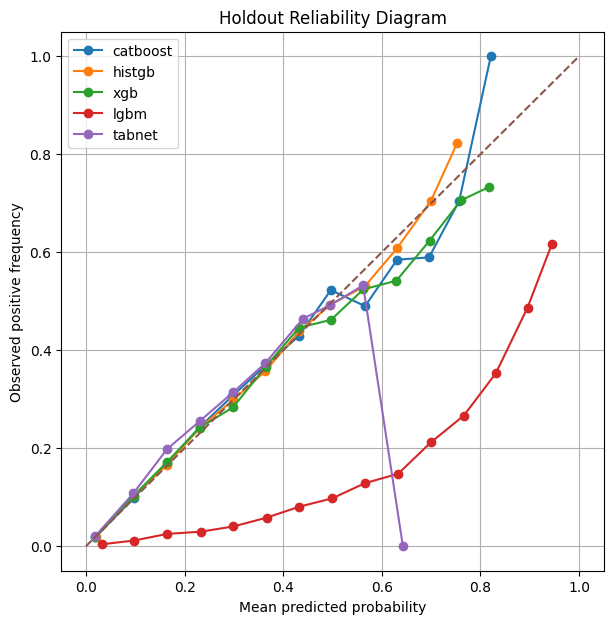

In [10]:
# =========================
# Module 26 — Expert correlation matrix
# =========================

expert_candidates = ["catboost", "histgb", "xgb", "lgbm", "tabnet", "mlp"]

corr_holdout = prediction_correlation_table(holdout_pred_df, expert_candidates)
corr_oof = prediction_correlation_table(oof_pred_df, expert_candidates)

print("OOF prediction correlation:")
display(corr_oof)

print("Holdout prediction correlation:")
display(corr_holdout)

# =========================
# Module 27 — Lower-correlation pairs
# =========================

def correlation_pairs(corr_df):
    rows = []
    cols = list(corr_df.columns)
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            rows.append({
                "model_a": cols[i],
                "model_b": cols[j],
                "spearman_corr": corr_df.iloc[i, j]
            })
    return pd.DataFrame(rows).sort_values("spearman_corr", ascending=True).reset_index(drop=True)

corr_pairs_holdout_df = correlation_pairs(corr_holdout)
corr_pairs_holdout_df

# =========================
# Module 28 — Top-k capture analysis
# =========================

def topk_capture_table(y_true, pred_df, model_names, top_fracs=(0.01, 0.05, 0.10)):
    y_true = np.asarray(y_true).astype(int)
    total_pos = y_true.sum()

    rows = []

    for model in model_names:
        probs = np.asarray(pred_df[model])
        n = len(probs)

        order = np.argsort(-probs)

        for frac in top_fracs:
            k = max(1, int(n * frac))
            idx = order[:k]

            captured_pos = y_true[idx].sum()
            capture_rate = captured_pos / total_pos if total_pos > 0 else np.nan
            precision_at_k = y_true[idx].mean()

            rows.append({
                "model": model,
                "top_frac": frac,
                "k": k,
                "captured_pos": int(captured_pos),
                "capture_rate": float(capture_rate),
                "precision_at_k": float(precision_at_k)
            })

    return pd.DataFrame(rows)

topk_models = ["catboost", "histgb", "xgb", "lgbm", "tabnet", "mlp"]

topk_holdout_df = topk_capture_table(
    y_true=y_holdout.values,
    pred_df=holdout_pred_df,
    model_names=topk_models,
    top_fracs=(0.01, 0.05, 0.10)
)

topk_holdout_df.sort_values(["top_frac", "capture_rate"], ascending=[True, False])

# =========================
# Module 29 — Threshold sweep
# =========================

def threshold_sweep(y_true, y_prob, thresholds=np.arange(0.05, 0.96, 0.05)):
    rows = []
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)

    for thr in thresholds:
        y_pred = (y_prob >= thr).astype(int)

        rows.append({
            "threshold": thr,
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0),
            "mcc": matthews_corrcoef(y_true, y_pred),
            "predicted_positive_rate": y_pred.mean()
        })

    return pd.DataFrame(rows)


threshold_models = ["catboost", "histgb", "xgb", "lgbm", "tabnet"]

threshold_tables = {}
for model in threshold_models:
    threshold_tables[model] = threshold_sweep(y_holdout.values, holdout_pred_df[model].values)

for model in threshold_models:
    print(f"\nThreshold table: {model}")
    display(threshold_tables[model].sort_values("f1", ascending=False).head(10))

# =========================
# Module 30 — Reliability diagrams
# =========================

import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

def plot_reliability_diagram(y_true, y_prob_dict, n_bins=15, title="Reliability Diagram"):
    plt.figure(figsize=(7, 7))

    for model_name, y_prob in y_prob_dict.items():
        frac_pos, mean_pred = calibration_curve(y_true, y_prob, n_bins=n_bins, strategy="uniform")
        plt.plot(mean_pred, frac_pos, marker="o", label=model_name)

    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlabel("Mean predicted probability")
    plt.ylabel("Observed positive frequency")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()


reliability_models = ["catboost", "histgb", "xgb", "lgbm", "tabnet"]

plot_reliability_diagram(
    y_true=y_holdout.values,
    y_prob_dict={m: holdout_pred_df[m].values for m in reliability_models},
    n_bins=15,
    title="Holdout Reliability Diagram"
)

In [11]:
# =========================
# Module 31 — Specialized CatBoost experts
# =========================

def get_specialized_catboost_registry(seed=42):
    registry = {
        "cb_balanced": {
            "family": "specialized_boosting",
            "preproc": "tree",
            "estimator": CatBoostClassifier(
                iterations=400,
                learning_rate=0.05,
                depth=6,
                loss_function="Logloss",
                eval_metric="AUC",
                verbose=0,
                random_seed=seed
            )
        },

        # more emphasis on positives -> should push recall up
        "cb_recall": {
            "family": "specialized_boosting",
            "preproc": "tree",
            "estimator": CatBoostClassifier(
                iterations=400,
                learning_rate=0.05,
                depth=6,
                loss_function="Logloss",
                eval_metric="AUC",
                auto_class_weights="Balanced",
                verbose=0,
                random_seed=seed
            )
        },

        # less aggressive / more conservative probability structure
        "cb_precision": {
            "family": "specialized_boosting",
            "preproc": "tree",
            "estimator": CatBoostClassifier(
                iterations=500,
                learning_rate=0.03,
                depth=5,
                loss_function="Logloss",
                eval_metric="AUC",
                l2_leaf_reg=8.0,
                random_strength=2.0,
                verbose=0,
                random_seed=seed
            )
        }
    }
    return registry

SPECIALIZED_CB_REGISTRY = get_specialized_catboost_registry(seed=SEED)
print(list(SPECIALIZED_CB_REGISTRY.keys()))

# =========================
# Module 32 — Threshold selection helpers
# =========================

def find_best_threshold_for_metric(y_true, y_prob, metric="f1", thresholds=None):
    if thresholds is None:
        thresholds = np.arange(0.05, 0.96, 0.01)

    best_thr = None
    best_score = -np.inf
    rows = []

    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)

    for thr in thresholds:
        y_pred = (y_prob >= thr).astype(int)

        precision = precision_score(y_true, y_pred, zero_division=0)
        recall = recall_score(y_true, y_pred, zero_division=0)
        f1 = f1_score(y_true, y_pred, zero_division=0)
        mcc = matthews_corrcoef(y_true, y_pred)

        row = {
            "threshold": thr,
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "mcc": mcc
        }
        rows.append(row)

        score = row[metric]
        if score > best_score:
            best_score = score
            best_thr = thr

    return best_thr, best_score, pd.DataFrame(rows)


def find_threshold_for_target_recall(y_true, y_prob, target_recall=0.80, thresholds=None):
    if thresholds is None:
        thresholds = np.arange(0.01, 0.96, 0.01)

    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)

    feasible = []
    for thr in thresholds:
        y_pred = (y_prob >= thr).astype(int)
        precision = precision_score(y_true, y_pred, zero_division=0)
        recall = recall_score(y_true, y_pred, zero_division=0)
        f1 = f1_score(y_true, y_pred, zero_division=0)
        mcc = matthews_corrcoef(y_true, y_pred)

        feasible.append({
            "threshold": thr,
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "mcc": mcc
        })

    df = pd.DataFrame(feasible)

    df_ok = df[df["recall"] >= target_recall].copy()
    if len(df_ok) == 0:
        # fallback: closest recall
        idx = (df["recall"] - target_recall).abs().idxmin()
        best_row = df.loc[idx]
    else:
        # among feasible thresholds, maximize precision
        idx = df_ok["precision"].idxmax()
        best_row = df_ok.loc[idx]

    return float(best_row["threshold"]), best_row.to_dict(), df


def find_threshold_for_target_precision(y_true, y_prob, target_precision=0.50, thresholds=None):
    if thresholds is None:
        thresholds = np.arange(0.01, 0.96, 0.01)

    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)

    feasible = []
    for thr in thresholds:
        y_pred = (y_prob >= thr).astype(int)
        precision = precision_score(y_true, y_pred, zero_division=0)
        recall = recall_score(y_true, y_pred, zero_division=0)
        f1 = f1_score(y_true, y_pred, zero_division=0)
        mcc = matthews_corrcoef(y_true, y_pred)

        feasible.append({
            "threshold": thr,
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "mcc": mcc
        })

    df = pd.DataFrame(feasible)

    df_ok = df[df["precision"] >= target_precision].copy()
    if len(df_ok) == 0:
        idx = (df["precision"] - target_precision).abs().idxmin()
        best_row = df.loc[idx]
    else:
        # among feasible thresholds, maximize recall
        idx = df_ok["recall"].idxmax()
        best_row = df_ok.loc[idx]

    return float(best_row["threshold"]), best_row.to_dict(), df

# =========================
# Module 33 — CV for specialized experts
# =========================

spec_oof_preds, spec_fold_metrics_df, spec_cv_summary_df, spec_dev_oof_results_df = run_benchmark_cv(
    X_dev_df=X_dev_enc,
    y_dev=y_dev,
    model_registry=SPECIALIZED_CB_REGISTRY,
    n_splits=N_SPLITS,
    seed=SEED
)

print("Specialized expert OOF results:")
display(spec_dev_oof_results_df.sort_values("PR_AUC", ascending=False))

# =========================
# Module 34 — OOF threshold selection
# =========================

specialized_thresholds = {}

# balanced expert -> maximize F1 on OOF
thr_bal, score_bal, df_bal = find_best_threshold_for_metric(
    y_true=y_dev.values,
    y_prob=spec_oof_preds["cb_balanced"],
    metric="f1"
)
specialized_thresholds["cb_balanced"] = {
    "strategy": "best_f1",
    "threshold": thr_bal,
    "score": score_bal
}

# recall expert -> target high recall
thr_rec, row_rec, df_rec = find_threshold_for_target_recall(
    y_true=y_dev.values,
    y_prob=spec_oof_preds["cb_recall"],
    target_recall=0.80
)
specialized_thresholds["cb_recall"] = {
    "strategy": "target_recall_0.80",
    "threshold": thr_rec,
    "selected_row": row_rec
}

# precision expert -> target precision
thr_pre, row_pre, df_pre = find_threshold_for_target_precision(
    y_true=y_dev.values,
    y_prob=spec_oof_preds["cb_precision"],
    target_precision=0.50
)
specialized_thresholds["cb_precision"] = {
    "strategy": "target_precision_0.50",
    "threshold": thr_pre,
    "selected_row": row_pre
}

specialized_thresholds

# =========================
# Module 35 — OOF specialized operating points
# =========================

def evaluate_at_threshold(y_true, y_prob, threshold):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)
    y_pred = (y_prob >= threshold).astype(int)

    return {
        "threshold": threshold,
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "mcc": matthews_corrcoef(y_true, y_pred),
        "predicted_positive_rate": y_pred.mean()
    }

specialized_dev_rows = []

for model_name in ["cb_balanced", "cb_recall", "cb_precision"]:
    thr = specialized_thresholds[model_name]["threshold"]
    row = {"model": model_name}
    row.update(evaluate_at_threshold(y_dev.values, spec_oof_preds[model_name], thr))
    specialized_dev_rows.append(row)

specialized_dev_operating_df = pd.DataFrame(specialized_dev_rows)
display(specialized_dev_operating_df)

['cb_balanced', 'cb_recall', 'cb_precision']
Running CV for: cb_balanced
Fold 1 | PR_AUC=0.379606 | ROC_AUC=0.852008 | Brier=0.069583
Fold 2 | PR_AUC=0.388361 | ROC_AUC=0.853968 | Brier=0.069180
Fold 3 | PR_AUC=0.368529 | ROC_AUC=0.846186 | Brier=0.070411
Fold 4 | PR_AUC=0.384571 | ROC_AUC=0.856038 | Brier=0.069304
Fold 5 | PR_AUC=0.366482 | ROC_AUC=0.843325 | Brier=0.070628
OOF summary:
model        cb_balanced
PR_AUC           0.37721
ROC_AUC          0.85029
Brier           0.069821
ECE             0.002307
NLL             0.235835
F1              0.175723
Precision       0.572253
Recall          0.103798
Accuracy        0.908285
MCC             0.215781
dtype: object
Running CV for: cb_recall
Fold 1 | PR_AUC=0.379694 | ROC_AUC=0.851546 | Brier=0.162311
Fold 2 | PR_AUC=0.390887 | ROC_AUC=0.853718 | Brier=0.162736
Fold 3 | PR_AUC=0.369909 | ROC_AUC=0.846058 | Brier=0.165517
Fold 4 | PR_AUC=0.383641 | ROC_AUC=0.855732 | Brier=0.162372
Fold 5 | PR_AUC=0.367316 | ROC_AUC=0.842689 | Brie

,model,PR_AUC,ROC_AUC,Brier,ECE,NLL,F1,Precision,Recall,Accuracy,MCC
0,cb_precision,0.379356,0.850377,0.069752,0.002822,0.235723,0.169520,0.573627,0.099456,0.908221,0.211492
1,cb_recall,0.377885,0.849923,0.163154,0.246847,0.478863,0.371729,0.241230,0.809825,0.742180,0.342329
2,cb_balanced,0.377210,0.850290,0.069821,0.002307,0.235835,0.175723,0.572253,0.103798,0.908285,0.215781


,model,threshold,precision,recall,f1,mcc,predicted_positive_rate
0,cb_balanced,0.21,0.341880,0.546197,0.420535,0.356901,0.150470
1,cb_recall,0.51,0.244686,0.801036,0.374865,0.344030,0.308331
2,cb_precision,0.40,0.502837,0.204039,0.290287,0.278894,0.038217


In [12]:
# =========================
# Module 36 — Holdout evaluation for specialized experts
# =========================

spec_fitted_models, spec_holdout_probs, spec_holdout_results_df = fit_full_and_evaluate_holdout(
    X_dev_df=X_dev_enc,
    y_dev=y_dev,
    X_holdout_df=X_holdout_enc,
    y_holdout=y_holdout,
    model_registry=SPECIALIZED_CB_REGISTRY
)

print("Specialized experts holdout probability metrics:")
display(spec_holdout_results_df.sort_values("PR_AUC", ascending=False))

# =========================
# Module 37 — Holdout operating points
# =========================

specialized_holdout_rows = []

for model_name in ["cb_balanced", "cb_recall", "cb_precision"]:
    thr = specialized_thresholds[model_name]["threshold"]
    row = {"model": model_name, "threshold_from_oof": thr}
    row.update(evaluate_at_threshold(y_holdout.values, spec_holdout_probs[model_name], thr))
    specialized_holdout_rows.append(row)

specialized_holdout_operating_df = pd.DataFrame(specialized_holdout_rows)
display(specialized_holdout_operating_df)

# =========================
# Module 38 — Correlation among specialized experts
# =========================

spec_oof_pred_df = pd.DataFrame({
    "cb_balanced": spec_oof_preds["cb_balanced"],
    "cb_recall": spec_oof_preds["cb_recall"],
    "cb_precision": spec_oof_preds["cb_precision"]
}, index=X_dev_enc.index)

spec_holdout_pred_df = pd.DataFrame({
    "cb_balanced": spec_holdout_probs["cb_balanced"],
    "cb_recall": spec_holdout_probs["cb_recall"],
    "cb_precision": spec_holdout_probs["cb_precision"]
}, index=X_holdout_enc.index)

print("OOF specialized expert correlation:")
display(spec_oof_pred_df.corr(method="spearman"))

print("Holdout specialized expert correlation:")
display(spec_holdout_pred_df.corr(method="spearman"))

# =========================
# Module 39 — Top-k capture for specialized experts
# =========================

spec_topk_holdout_df = topk_capture_table(
    y_true=y_holdout.values,
    pred_df=spec_holdout_pred_df,
    model_names=["cb_balanced", "cb_recall", "cb_precision"],
    top_fracs=(0.01, 0.05, 0.10)
)

display(spec_topk_holdout_df.sort_values(["top_frac", "capture_rate"], ascending=[True, False]))

Training full-dev and evaluating holdout: cb_balanced
model        cb_balanced
PR_AUC          0.373462
ROC_AUC         0.851145
Brier           0.069909
ECE             0.003509
NLL             0.235837
F1              0.172805
Precision       0.561565
Recall          0.102113
Accuracy        0.907915
MCC             0.211221
dtype: object
Training full-dev and evaluating holdout: cb_recall
model        cb_recall
PR_AUC        0.372319
ROC_AUC       0.850978
Brier         0.163109
ECE           0.247133
NLL           0.479145
F1            0.374165
Precision     0.242857
Recall        0.814606
Accuracy      0.743318
MCC           0.345893
dtype: object
Training full-dev and evaluating holdout: cb_precision
model        cb_precision
PR_AUC           0.372821
ROC_AUC          0.850903
Brier            0.069924
ECE              0.003775
NLL              0.235979
F1               0.167914
Precision        0.566787
Recall           0.098556
Accuracy         0.907994
MCC               0.208

,model,PR_AUC,ROC_AUC,Brier,ECE,NLL,F1,Precision,Recall,Accuracy,MCC
0,cb_balanced,0.373462,0.851145,0.069909,0.003509,0.235837,0.172805,0.561565,0.102113,0.907915,0.211221
1,cb_precision,0.372821,0.850903,0.069924,0.003775,0.235979,0.167914,0.566787,0.098556,0.907994,0.208780
2,cb_recall,0.372319,0.850978,0.163109,0.247133,0.479145,0.374165,0.242857,0.814606,0.743318,0.345893


,model,threshold_from_oof,threshold,precision,recall,f1,mcc,predicted_positive_rate
0,cb_balanced,0.21,0.21,0.346728,0.548860,0.424984,0.361911,0.149105
1,cb_recall,0.51,0.51,0.246026,0.806445,0.377030,0.347399,0.308755
2,cb_precision,0.40,0.40,0.495833,0.199205,0.284222,0.272696,0.037843


OOF specialized expert correlation:


,cb_balanced,cb_recall,cb_precision
cb_balanced,1.000000,0.995665,0.998205
cb_recall,0.995665,1.000000,0.994339
cb_precision,0.998205,0.994339,1.000000


Holdout specialized expert correlation:


,cb_balanced,cb_recall,cb_precision
cb_balanced,1.000000,0.996414,0.998491
cb_recall,0.996414,1.000000,0.995082
cb_precision,0.998491,0.995082,1.000000


,model,top_frac,k,captured_pos,capture_rate,precision_at_k
3,cb_recall,0.01,507,294,0.061519,0.579882
0,cb_balanced,0.01,507,292,0.061101,0.575937
6,cb_precision,0.01,507,292,0.061101,0.575937
4,cb_recall,0.05,2536,1197,0.250471,0.472003
1,cb_balanced,0.05,2536,1180,0.246914,0.465300
7,cb_precision,0.05,2536,1179,0.246704,0.464905
8,cb_precision,0.10,5073,2014,0.421427,0.397004
2,cb_balanced,0.10,5073,2002,0.418916,0.394638
5,cb_recall,0.10,5073,1998,0.418079,0.393850


In [13]:
# =========================
# Module 40 — Hard-sample weighting utility
# =========================

def make_diversity_sample_weights(
    y_true,
    y_prob,
    base_threshold=0.5,
    fn_boost=4.0,
    fp_boost=2.0,
    hard_band=(0.35, 0.65),
    hard_band_boost=1.5,
    base_weight=1.0
):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)
    y_pred = (y_prob >= base_threshold).astype(int)

    weights = np.ones_like(y_prob, dtype=float) * base_weight

    false_negative = (y_true == 1) & (y_pred == 0)
    false_positive = (y_true == 0) & (y_pred == 1)
    hard_band_mask = (y_prob >= hard_band[0]) & (y_prob <= hard_band[1])

    weights[false_negative] *= fn_boost
    weights[false_positive] *= fp_boost
    weights[hard_band_mask] *= hard_band_boost

    return weights

# =========================
# Module 41 — Feature-group discovery
# =========================

def group_features_by_keywords(columns):
    groups = {
        "demographic": [],
        "lifestyle": [],
        "medical": [],
        "general_health": []
    }

    demographic_kw = ["age", "sex", "gender", "race", "marital", "education", "income"]
    lifestyle_kw = ["smoke", "alcohol", "drink", "exercise", "physicalactivity", "fruit", "vege", "sleep", "activity"]
    medical_kw = ["stroke", "diabetic", "diabetes", "asthma", "kidney", "skin", "heart", "attack", "bmi"]
    general_kw = ["genhealth", "mental", "physical", "diffwalk"]

    for col in columns:
        c = col.lower()

        assigned = False
        if any(k in c for k in demographic_kw):
            groups["demographic"].append(col)
            assigned = True
        if any(k in c for k in lifestyle_kw):
            groups["lifestyle"].append(col)
            assigned = True
        if any(k in c for k in medical_kw):
            groups["medical"].append(col)
            assigned = True
        if any(k in c for k in general_kw):
            groups["general_health"].append(col)
            assigned = True

        # if not assigned, leave it out for now

    return groups

FEATURE_GROUPS = group_features_by_keywords(X_dev_enc.columns.tolist())

for g, cols in FEATURE_GROUPS.items():
    print(f"{g}: {len(cols)} columns")
    print(cols[:10], "\n")

# =========================
# Module 42 — Controlled perturbation utility
# =========================

def add_gaussian_noise_to_dataframe(X_df, noise_std=0.01, random_state=42):
    rng = np.random.default_rng(random_state)
    X_noisy = X_df.copy()

    arr = X_noisy.values.astype(np.float32)
    noise = rng.normal(loc=0.0, scale=noise_std, size=arr.shape).astype(np.float32)

    arr_noisy = arr + noise
    X_noisy.iloc[:, :] = arr_noisy

    return X_noisy

# =========================
# Module 43 — Flexible diverse fold runner
# =========================

def run_single_fold_diverse(
    model_name,
    estimator,
    X_dev_df,
    y_dev,
    tr_idx,
    va_idx,
    fold_id,
    preproc_name="tree",
    feature_subset=None,
    sample_weights_full=None,
    train_noise_std=None,
    random_state=42
):
    X_tr_df = X_dev_df.iloc[tr_idx].copy()
    y_tr = y_dev.iloc[tr_idx].copy()
    X_va_df = X_dev_df.iloc[va_idx].copy()
    y_va = y_dev.iloc[va_idx].copy()

    if feature_subset is not None:
        X_tr_df = X_tr_df[feature_subset].copy()
        X_va_df = X_va_df[feature_subset].copy()

    if train_noise_std is not None and train_noise_std > 0:
        X_tr_df = add_gaussian_noise_to_dataframe(
            X_tr_df,
            noise_std=train_noise_std,
            random_state=random_state + fold_id
        )

    X_tr_np, X_va_np, preprocessor = prepare_fold_data(
        X_tr_df, X_va_df, preproc_name
    )

    model = clone(estimator)

    fit_kwargs = {}
    if sample_weights_full is not None:
        fit_kwargs["sample_weight"] = np.asarray(sample_weights_full)[tr_idx]

    try:
        model.fit(X_tr_np, y_tr, **fit_kwargs)
    except TypeError:
        model.fit(X_tr_np, y_tr)

    va_prob = get_positive_proba(model, X_va_np)
    fold_metrics = compute_metrics(y_va, va_prob)
    fold_metrics["fold"] = fold_id

    return {
        "va_idx": va_idx,
        "valid_prob": np.asarray(va_prob),
        "fold_metrics": fold_metrics
    }

# =========================
# Module 43 — Flexible diverse fold runner
# =========================

def run_single_fold_diverse(
    model_name,
    estimator,
    X_dev_df,
    y_dev,
    tr_idx,
    va_idx,
    fold_id,
    preproc_name="tree",
    feature_subset=None,
    sample_weights_full=None,
    train_noise_std=None,
    random_state=42
):
    X_tr_df = X_dev_df.iloc[tr_idx].copy()
    y_tr = y_dev.iloc[tr_idx].copy()
    X_va_df = X_dev_df.iloc[va_idx].copy()
    y_va = y_dev.iloc[va_idx].copy()

    if feature_subset is not None:
        X_tr_df = X_tr_df[feature_subset].copy()
        X_va_df = X_va_df[feature_subset].copy()

    if train_noise_std is not None and train_noise_std > 0:
        X_tr_df = add_gaussian_noise_to_dataframe(
            X_tr_df,
            noise_std=train_noise_std,
            random_state=random_state + fold_id
        )

    X_tr_np, X_va_np, preprocessor = prepare_fold_data(
        X_tr_df, X_va_df, preproc_name
    )

    model = clone(estimator)

    fit_kwargs = {}
    if sample_weights_full is not None:
        fit_kwargs["sample_weight"] = np.asarray(sample_weights_full)[tr_idx]

    try:
        model.fit(X_tr_np, y_tr, **fit_kwargs)
    except TypeError:
        model.fit(X_tr_np, y_tr)

    va_prob = get_positive_proba(model, X_va_np)
    fold_metrics = compute_metrics(y_va, va_prob)
    fold_metrics["fold"] = fold_id

    return {
        "va_idx": va_idx,
        "valid_prob": np.asarray(va_prob),
        "fold_metrics": fold_metrics
    }

# =========================
# Module 44 — Flexible CV runner for diverse experts
# =========================

def run_diverse_expert_cv(
    expert_name,
    estimator,
    X_dev_df,
    y_dev,
    preproc_name="tree",
    feature_subset=None,
    sample_weights_full=None,
    train_noise_std=None,
    n_splits=5,
    seed=42
):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    split_list = list(skf.split(X_dev_df, y_dev))

    oof_pred = np.zeros(len(X_dev_df), dtype=float)
    fold_rows = []

    for fold_id, (tr_idx, va_idx) in enumerate(split_list, start=1):
        out = run_single_fold_diverse(
            model_name=expert_name,
            estimator=estimator,
            X_dev_df=X_dev_df,
            y_dev=y_dev,
            tr_idx=tr_idx,
            va_idx=va_idx,
            fold_id=fold_id,
            preproc_name=preproc_name,
            feature_subset=feature_subset,
            sample_weights_full=sample_weights_full,
            train_noise_std=train_noise_std,
            random_state=seed
        )

        oof_pred[out["va_idx"]] = out["valid_prob"]

        row = {"model": expert_name}
        row.update(out["fold_metrics"])
        fold_rows.append(row)

        print(
            f"{expert_name} | fold {fold_id} | "
            f"PR_AUC={row['PR_AUC']:.6f} | "
            f"ROC_AUC={row['ROC_AUC']:.6f} | "
            f"Brier={row['Brier']:.6f}"
        )

    fold_df = pd.DataFrame(fold_rows)
    oof_row = {"model": expert_name}
    oof_row.update(compute_metrics(y_dev, oof_pred))

    return oof_pred, fold_df, pd.DataFrame([oof_row])

# =========================
# Module 45 — Diverse expert definitions
# =========================

CB_BASE_EST = CatBoostClassifier(
    iterations=400,
    learning_rate=0.05,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    verbose=0,
    random_seed=SEED
)

CB_HARDRW_EST = CatBoostClassifier(
    iterations=400,
    learning_rate=0.05,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    verbose=0,
    random_seed=SEED
)

CB_SUBSPACE_EST = CatBoostClassifier(
    iterations=400,
    learning_rate=0.05,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    verbose=0,
    random_seed=SEED
)

CB_NOISY_EST = CatBoostClassifier(
    iterations=400,
    learning_rate=0.05,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    verbose=0,
    random_seed=SEED
)

# =========================
# Module 46 — Build hard-sample weights
# =========================

reference_oof_name = "catboost"
reference_oof_prob = all_oof_preds[reference_oof_name]

diversity_sample_weights = make_diversity_sample_weights(
    y_true=y_dev.values,
    y_prob=reference_oof_prob,
    base_threshold=0.5,
    fn_boost=4.0,
    fp_boost=2.0,
    hard_band=(0.30, 0.70),
    hard_band_boost=1.5,
    base_weight=1.0
)

pd.Series(diversity_sample_weights).describe()

# =========================
# Module 47 — Run diversity-driven experts
# =========================

diverse_oof_preds = {}
diverse_dev_rows = []
diverse_fold_tables = {}

# 1) Base expert
oof_base, fold_base, row_base = run_diverse_expert_cv(
    expert_name="cb_base_div",
    estimator=CB_BASE_EST,
    X_dev_df=X_dev_enc,
    y_dev=y_dev,
    preproc_name="tree",
    feature_subset=None,
    sample_weights_full=None,
    train_noise_std=None,
    n_splits=N_SPLITS,
    seed=SEED
)
diverse_oof_preds["cb_base_div"] = oof_base
diverse_fold_tables["cb_base_div"] = fold_base
diverse_dev_rows.append(row_base)

# 2) Hard-reweighted expert
oof_hard, fold_hard, row_hard = run_diverse_expert_cv(
    expert_name="cb_hardrw_div",
    estimator=CB_HARDRW_EST,
    X_dev_df=X_dev_enc,
    y_dev=y_dev,
    preproc_name="tree",
    feature_subset=None,
    sample_weights_full=diversity_sample_weights,
    train_noise_std=None,
    n_splits=N_SPLITS,
    seed=SEED
)
diverse_oof_preds["cb_hardrw_div"] = oof_hard
diverse_fold_tables["cb_hardrw_div"] = fold_hard
diverse_dev_rows.append(row_hard)

# 3) Demographic subspace expert
demo_cols = FEATURE_GROUPS["demographic"]
if len(demo_cols) > 0:
    oof_demo, fold_demo, row_demo = run_diverse_expert_cv(
        expert_name="cb_demo_div",
        estimator=CB_SUBSPACE_EST,
        X_dev_df=X_dev_enc,
        y_dev=y_dev,
        preproc_name="tree",
        feature_subset=demo_cols,
        sample_weights_full=None,
        train_noise_std=None,
        n_splits=N_SPLITS,
        seed=SEED
    )
    diverse_oof_preds["cb_demo_div"] = oof_demo
    diverse_fold_tables["cb_demo_div"] = fold_demo
    diverse_dev_rows.append(row_demo)

# 4) Lifestyle subspace expert
life_cols = FEATURE_GROUPS["lifestyle"]
if len(life_cols) > 0:
    oof_life, fold_life, row_life = run_diverse_expert_cv(
        expert_name="cb_lifestyle_div",
        estimator=CB_SUBSPACE_EST,
        X_dev_df=X_dev_enc,
        y_dev=y_dev,
        preproc_name="tree",
        feature_subset=life_cols,
        sample_weights_full=None,
        train_noise_std=None,
        n_splits=N_SPLITS,
        seed=SEED
    )
    diverse_oof_preds["cb_lifestyle_div"] = oof_life
    diverse_fold_tables["cb_lifestyle_div"] = fold_life
    diverse_dev_rows.append(row_life)

# 5) Medical subspace expert
med_cols = FEATURE_GROUPS["medical"]
if len(med_cols) > 0:
    oof_med, fold_med, row_med = run_diverse_expert_cv(
        expert_name="cb_medical_div",
        estimator=CB_SUBSPACE_EST,
        X_dev_df=X_dev_enc,
        y_dev=y_dev,
        preproc_name="tree",
        feature_subset=med_cols,
        sample_weights_full=None,
        train_noise_std=None,
        n_splits=N_SPLITS,
        seed=SEED
    )
    diverse_oof_preds["cb_medical_div"] = oof_med
    diverse_fold_tables["cb_medical_div"] = fold_med
    diverse_dev_rows.append(row_med)

# 6) Noisy training expert
oof_noisy, fold_noisy, row_noisy = run_diverse_expert_cv(
    expert_name="cb_noisy_div",
    estimator=CB_NOISY_EST,
    X_dev_df=X_dev_enc,
    y_dev=y_dev,
    preproc_name="tree",
    feature_subset=None,
    sample_weights_full=None,
    train_noise_std=0.01,
    n_splits=N_SPLITS,
    seed=SEED
)
diverse_oof_preds["cb_noisy_div"] = oof_noisy
diverse_fold_tables["cb_noisy_div"] = fold_noisy
diverse_dev_rows.append(row_noisy)

diverse_dev_results_df = pd.concat(diverse_dev_rows, axis=0).sort_values(
    ["PR_AUC", "ROC_AUC"], ascending=False
).reset_index(drop=True)

display(diverse_dev_results_df)

# =========================
# Module 48 — OOF correlation among diverse experts
# =========================

diverse_oof_pred_df = pd.DataFrame(index=X_dev_enc.index)
for name, pred in diverse_oof_preds.items():
    diverse_oof_pred_df[name] = pred
diverse_oof_pred_df["y_true"] = y_dev.values

diverse_corr_oof = diverse_oof_pred_df.drop(columns=["y_true"]).corr(method="spearman")
display(diverse_corr_oof)

# =========================
# Module 49 — OOF top-k capture among diverse experts
# =========================

diverse_topk_oof_df = topk_capture_table(
    y_true=y_dev.values,
    pred_df=diverse_oof_pred_df.drop(columns=["y_true"]),
    model_names=list(diverse_oof_preds.keys()),
    top_fracs=(0.01, 0.05, 0.10)
)

display(diverse_topk_oof_df.sort_values(["top_frac", "capture_rate"], ascending=[True, False]))

# =========================
# Module 50 — Full-dev fit and holdout prediction for diverse experts
# =========================

def fit_diverse_expert_full(
    expert_name,
    estimator,
    X_dev_df,
    y_dev,
    X_holdout_df,
    preproc_name="tree",
    feature_subset=None,
    sample_weights_full=None,
    train_noise_std=None,
    random_state=42
):
    X_tr_df = X_dev_df.copy()
    X_te_df = X_holdout_df.copy()

    if feature_subset is not None:
        X_tr_df = X_tr_df[feature_subset].copy()
        X_te_df = X_te_df[feature_subset].copy()

    if train_noise_std is not None and train_noise_std > 0:
        X_tr_df = add_gaussian_noise_to_dataframe(
            X_tr_df,
            noise_std=train_noise_std,
            random_state=random_state
        )

    X_tr_np, X_te_np, preprocessor = prepare_full_data(
        X_tr_df, X_te_df, preproc_name
    )

    model = clone(estimator)

    fit_kwargs = {}
    if sample_weights_full is not None:
        fit_kwargs["sample_weight"] = np.asarray(sample_weights_full)

    try:
        model.fit(X_tr_np, y_dev, **fit_kwargs)
    except TypeError:
        model.fit(X_tr_np, y_dev)

    hold_prob = get_positive_proba(model, X_te_np)
    return hold_prob

demographic: 4 columns
['Sex', 'Age', 'Education', 'Income'] 

lifestyle: 4 columns
['Smoker', 'PhysActivity', 'Fruits', 'HvyAlcoholConsump'] 

medical: 3 columns
['BMI', 'Stroke', 'Diabetes'] 

general_health: 1 columns
['DiffWalk'] 

cb_base_div | fold 1 | PR_AUC=0.379606 | ROC_AUC=0.852008 | Brier=0.069583
cb_base_div | fold 2 | PR_AUC=0.388361 | ROC_AUC=0.853968 | Brier=0.069180
cb_base_div | fold 3 | PR_AUC=0.368529 | ROC_AUC=0.846186 | Brier=0.070411
cb_base_div | fold 4 | PR_AUC=0.384571 | ROC_AUC=0.856038 | Brier=0.069304
cb_base_div | fold 5 | PR_AUC=0.366482 | ROC_AUC=0.843325 | Brier=0.070628
cb_hardrw_div | fold 1 | PR_AUC=0.328954 | ROC_AUC=0.846832 | Brier=0.098127
cb_hardrw_div | fold 2 | PR_AUC=0.330959 | ROC_AUC=0.848666 | Brier=0.098050
cb_hardrw_div | fold 3 | PR_AUC=0.320073 | ROC_AUC=0.841432 | Brier=0.100287
cb_hardrw_div | fold 4 | PR_AUC=0.328301 | ROC_AUC=0.850344 | Brier=0.097943
cb_hardrw_div | fold 5 | PR_AUC=0.314976 | ROC_AUC=0.837905 | Brier=0.099092
cb_d

,model,PR_AUC,ROC_AUC,Brier,ECE,NLL,F1,Precision,Recall,Accuracy,MCC
0,cb_noisy_div,0.378666,0.850213,0.069784,0.001847,0.235811,0.180133,0.575416,0.106780,0.908453,0.219745
1,cb_base_div,0.377210,0.850290,0.069821,0.002307,0.235835,0.175723,0.572253,0.103798,0.908285,0.215781
2,cb_hardrw_div,0.324191,0.845008,0.098700,0.126655,0.313110,0.413466,0.326733,0.562886,0.849589,0.350392
3,cb_demo_div,0.230643,0.775181,0.077984,0.001727,0.269036,0.000000,0.000000,0.000000,0.905792,-0.001601
4,cb_medical_div,0.225868,0.675339,0.079632,0.001849,0.287995,0.070407,0.498623,0.037878,0.905797,0.117544
5,cb_lifestyle_div,0.142984,0.633655,0.083483,0.000044,0.301723,0.000000,0.000000,0.000000,0.905816,0.000000


,cb_base_div,cb_hardrw_div,cb_demo_div,cb_lifestyle_div,cb_medical_div,cb_noisy_div
cb_base_div,1.000000,0.996912,0.814846,0.354862,0.424606,0.996924
cb_hardrw_div,0.996912,1.000000,0.814760,0.352748,0.417101,0.994415
cb_demo_div,0.814846,0.814760,1.000000,0.250307,0.231167,0.807203
cb_lifestyle_div,0.354862,0.352748,0.250307,1.000000,0.126892,0.360159
cb_medical_div,0.424606,0.417101,0.231167,0.126892,1.000000,0.424669
cb_noisy_div,0.996924,0.994415,0.807203,0.360159,0.424669,1.000000


,model,top_frac,k,captured_pos,capture_rate,precision_at_k
15,cb_noisy_div,0.01,2029,1246,0.065188,0.614096
0,cb_base_div,0.01,2029,1245,0.065136,0.613603
12,cb_medical_div,0.01,2029,997,0.052161,0.491375
3,cb_hardrw_div,0.01,2029,859,0.044941,0.423361
6,cb_demo_div,0.01,2029,608,0.031809,0.299655
9,cb_lifestyle_div,0.01,2029,362,0.018939,0.178413
16,cb_noisy_div,0.05,10147,4853,0.253898,0.478269
1,cb_base_div,0.05,10147,4831,0.252747,0.476101
4,cb_hardrw_div,0.05,10147,4047,0.211730,0.398837
13,cb_medical_div,0.05,10147,3509,0.183583,0.345816


In [14]:
# =========================
# Module 51 — Holdout results for diverse experts
# =========================

diverse_holdout_probs = {}
diverse_holdout_rows = []

# base
diverse_holdout_probs["cb_base_div"] = fit_diverse_expert_full(
    expert_name="cb_base_div",
    estimator=CB_BASE_EST,
    X_dev_df=X_dev_enc,
    y_dev=y_dev,
    X_holdout_df=X_holdout_enc,
    preproc_name="tree",
    feature_subset=None,
    sample_weights_full=None,
    train_noise_std=None,
    random_state=SEED
)

# hardrw
diverse_holdout_probs["cb_hardrw_div"] = fit_diverse_expert_full(
    expert_name="cb_hardrw_div",
    estimator=CB_HARDRW_EST,
    X_dev_df=X_dev_enc,
    y_dev=y_dev,
    X_holdout_df=X_holdout_enc,
    preproc_name="tree",
    feature_subset=None,
    sample_weights_full=diversity_sample_weights,
    train_noise_std=None,
    random_state=SEED
)

# demo
if "cb_demo_div" in diverse_oof_preds:
    diverse_holdout_probs["cb_demo_div"] = fit_diverse_expert_full(
        expert_name="cb_demo_div",
        estimator=CB_SUBSPACE_EST,
        X_dev_df=X_dev_enc,
        y_dev=y_dev,
        X_holdout_df=X_holdout_enc,
        preproc_name="tree",
        feature_subset=demo_cols,
        sample_weights_full=None,
        train_noise_std=None,
        random_state=SEED
    )

# lifestyle
if "cb_lifestyle_div" in diverse_oof_preds:
    diverse_holdout_probs["cb_lifestyle_div"] = fit_diverse_expert_full(
        expert_name="cb_lifestyle_div",
        estimator=CB_SUBSPACE_EST,
        X_dev_df=X_dev_enc,
        y_dev=y_dev,
        X_holdout_df=X_holdout_enc,
        preproc_name="tree",
        feature_subset=life_cols,
        sample_weights_full=None,
        train_noise_std=None,
        random_state=SEED
    )

# medical
if "cb_medical_div" in diverse_oof_preds:
    diverse_holdout_probs["cb_medical_div"] = fit_diverse_expert_full(
        expert_name="cb_medical_div",
        estimator=CB_SUBSPACE_EST,
        X_dev_df=X_dev_enc,
        y_dev=y_dev,
        X_holdout_df=X_holdout_enc,
        preproc_name="tree",
        feature_subset=med_cols,
        sample_weights_full=None,
        train_noise_std=None,
        random_state=SEED
    )

# noisy
diverse_holdout_probs["cb_noisy_div"] = fit_diverse_expert_full(
    expert_name="cb_noisy_div",
    estimator=CB_NOISY_EST,
    X_dev_df=X_dev_enc,
    y_dev=y_dev,
    X_holdout_df=X_holdout_enc,
    preproc_name="tree",
    feature_subset=None,
    sample_weights_full=None,
    train_noise_std=0.01,
    random_state=SEED
)

for name, prob in diverse_holdout_probs.items():
    row = {"model": name}
    row.update(compute_metrics(y_holdout, prob))
    diverse_holdout_rows.append(row)

diverse_holdout_results_df = pd.DataFrame(diverse_holdout_rows).sort_values(
    ["PR_AUC", "ROC_AUC"], ascending=False
).reset_index(drop=True)

display(diverse_holdout_results_df)

# =========================
# Module 52 — Holdout correlation among diverse experts
# =========================

diverse_holdout_pred_df = pd.DataFrame(index=X_holdout_enc.index)
for name, pred in diverse_holdout_probs.items():
    diverse_holdout_pred_df[name] = pred
diverse_holdout_pred_df["y_true"] = y_holdout.values

diverse_corr_holdout = diverse_holdout_pred_df.drop(columns=["y_true"]).corr(method="spearman")
display(diverse_corr_holdout)

# =========================
# Module 53 — Holdout top-k capture among diverse experts
# =========================

diverse_topk_holdout_df = topk_capture_table(
    y_true=y_holdout.values,
    pred_df=diverse_holdout_pred_df.drop(columns=["y_true"]),
    model_names=list(diverse_holdout_probs.keys()),
    top_fracs=(0.01, 0.05, 0.10)
)

display(diverse_topk_holdout_df.sort_values(["top_frac", "capture_rate"], ascending=[True, False]))

,model,PR_AUC,ROC_AUC,Brier,ECE,NLL,F1,Precision,Recall,Accuracy,MCC
0,cb_base_div,0.373462,0.851145,0.069909,0.003509,0.235837,0.172805,0.561565,0.102113,0.907915,0.211221
1,cb_noisy_div,0.372338,0.850443,0.069960,0.002538,0.236212,0.180227,0.550214,0.107763,0.907659,0.214032
2,cb_hardrw_div,0.333167,0.847735,0.098035,0.126318,0.311603,0.423033,0.333333,0.578782,0.851289,0.362020
3,cb_demo_div,0.234056,0.773574,0.078008,0.001960,0.269548,0.000000,0.000000,0.000000,0.905807,0.000000
4,cb_medical_div,0.228073,0.673108,0.079470,0.003684,0.287520,0.071847,0.536443,0.038502,0.906299,0.124911
5,cb_lifestyle_div,0.137193,0.627685,0.083646,0.002027,0.302682,0.000000,0.000000,0.000000,0.905807,0.000000


,cb_base_div,cb_hardrw_div,cb_demo_div,cb_lifestyle_div,cb_medical_div,cb_noisy_div
cb_base_div,1.000000,0.997089,0.813847,0.353894,0.415559,0.997249
cb_hardrw_div,0.997089,1.000000,0.815180,0.352445,0.408872,0.994744
cb_demo_div,0.813847,0.815180,1.000000,0.250301,0.224287,0.805261
cb_lifestyle_div,0.353894,0.352445,0.250301,1.000000,0.117642,0.355391
cb_medical_div,0.415559,0.408872,0.224287,0.117642,1.000000,0.421040
cb_noisy_div,0.997249,0.994744,0.805261,0.355391,0.421040,1.000000


,model,top_frac,k,captured_pos,capture_rate,precision_at_k
15,cb_noisy_div,0.01,507,301,0.062984,0.593688
0,cb_base_div,0.01,507,292,0.061101,0.575937
12,cb_medical_div,0.01,507,261,0.054614,0.514793
3,cb_hardrw_div,0.01,507,227,0.047499,0.447732
6,cb_demo_div,0.01,507,171,0.035782,0.337278
9,cb_lifestyle_div,0.01,507,86,0.017995,0.169625
1,cb_base_div,0.05,2536,1180,0.246914,0.465300
16,cb_noisy_div,0.05,2536,1173,0.245449,0.462539
4,cb_hardrw_div,0.05,2536,1045,0.218665,0.412066
13,cb_medical_div,0.05,2536,890,0.186231,0.350946


In [15]:
# =========================
# Module 54 — Final expert set
# =========================

FINAL_EXPERTS = ["cb_base_div", "cb_noisy_div", "cb_hardrw_div", "cb_medical_div"]
print(FINAL_EXPERTS)

# =========================
# Module 55 — Expert prediction tables
# =========================

moe_oof_expert_df = diverse_oof_pred_df[FINAL_EXPERTS].copy()
moe_oof_expert_df["y_true"] = y_dev.values

moe_holdout_expert_df = diverse_holdout_pred_df[FINAL_EXPERTS].copy()
moe_holdout_expert_df["y_true"] = y_holdout.values

print("OOF expert table shape:", moe_oof_expert_df.shape)
print("Holdout expert table shape:", moe_holdout_expert_df.shape)

display(moe_oof_expert_df.head())
display(moe_holdout_expert_df.head())

# =========================
# Module 56 — Gate meta-features
# =========================

def build_gate_features(expert_pred_df, expert_names):
    X_gate = expert_pred_df[expert_names].copy()

    X_gate["prob_mean"] = X_gate.mean(axis=1)
    X_gate["prob_std"] = X_gate.std(axis=1)
    X_gate["prob_min"] = X_gate.min(axis=1)
    X_gate["prob_max"] = X_gate.max(axis=1)
    X_gate["prob_range"] = X_gate["prob_max"] - X_gate["prob_min"]

    # pairwise absolute disagreements
    for i in range(len(expert_names)):
        for j in range(i + 1, len(expert_names)):
            a = expert_names[i]
            b = expert_names[j]
            X_gate[f"absdiff_{a}_{b}"] = (expert_pred_df[a] - expert_pred_df[b]).abs()

    return X_gate

X_gate_oof = build_gate_features(moe_oof_expert_df, FINAL_EXPERTS)
X_gate_holdout = build_gate_features(moe_holdout_expert_df, FINAL_EXPERTS)

y_gate_oof = moe_oof_expert_df["y_true"].values.astype(np.float32)
y_gate_holdout = moe_holdout_expert_df["y_true"].values.astype(np.float32)

print("Gate OOF shape:", X_gate_oof.shape)
print("Gate holdout shape:", X_gate_holdout.shape)
display(X_gate_oof.head())

# =========================
# Module 57 — Gate dataset
# =========================

class GatedMoEDataset(Dataset):
    def __init__(self, X_gate, expert_probs, y):
        if isinstance(X_gate, pd.DataFrame):
            X_gate = X_gate.values
        if isinstance(expert_probs, pd.DataFrame):
            expert_probs = expert_probs.values

        self.X_gate = torch.tensor(np.asarray(X_gate), dtype=torch.float32)
        self.expert_probs = torch.tensor(np.asarray(expert_probs), dtype=torch.float32)
        self.y = torch.tensor(np.asarray(y), dtype=torch.float32)

    def __len__(self):
        return len(self.X_gate)

    def __getitem__(self, idx):
        return self.X_gate[idx], self.expert_probs[idx], self.y[idx]

# =========================
# Module 58 — Gate network
# =========================

class TrustworthyGateNet(nn.Module):
    def __init__(self, input_dim, n_experts, hidden_dims=(64, 32), dropout=0.2):
        super().__init__()

        layers = []
        prev = input_dim
        for h in hidden_dims:
            layers.extend([
                nn.Linear(prev, h),
                nn.ReLU(),
                nn.BatchNorm1d(h),
                nn.Dropout(dropout)
            ])
            prev = h

        self.backbone = nn.Sequential(*layers)
        self.out = nn.Linear(prev, n_experts)

    def forward(self, x):
        h = self.backbone(x)
        gate_logits = self.out(h)
        gate_weights = torch.softmax(gate_logits, dim=1)
        return gate_weights

# =========================
# Module 59 — Prediction-level MoE
# =========================

class PredictionLevelMoE(nn.Module):
    def __init__(self, gate_input_dim, n_experts, hidden_dims=(64, 32), dropout=0.2):
        super().__init__()
        self.gate = TrustworthyGateNet(
            input_dim=gate_input_dim,
            n_experts=n_experts,
            hidden_dims=hidden_dims,
            dropout=dropout
        )

    def forward(self, x_gate, expert_probs):
        gate_weights = self.gate(x_gate)  # [B, E]

        # weighted mixture of expert probabilities
        mixed_prob = torch.sum(gate_weights * expert_probs, dim=1)

        return {
            "mixed_prob": mixed_prob,
            "gate_weights": gate_weights
        }

# =========================
# Module 60 — MoE training utility
# =========================

def train_prediction_moe(
    model,
    X_gate_train,
    expert_probs_train,
    y_train,
    X_gate_valid,
    expert_probs_valid,
    y_valid,
    epochs=20,
    batch_size=2048,
    lr=1e-3,
    weight_decay=1e-5,
    entropy_reg=0.001,
    patience=5,
    device=None
):
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)

    ds_train = GatedMoEDataset(X_gate_train, expert_probs_train, y_train)
    ds_valid = GatedMoEDataset(X_gate_valid, expert_probs_valid, y_valid)

    dl_train = DataLoader(ds_train, batch_size=batch_size, shuffle=True, drop_last=False)
    dl_valid = DataLoader(ds_valid, batch_size=batch_size, shuffle=False, drop_last=False)

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    best_state = None
    best_pr_auc = -np.inf
    wait = 0

    for epoch in range(1, epochs + 1):
        model.train()
        train_losses = []

        for xb_gate, xb_exp, yb in dl_train:
            xb_gate = xb_gate.to(device)
            xb_exp = xb_exp.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()

            out = model(xb_gate, xb_exp)
            pred = torch.clamp(out["mixed_prob"], 1e-6, 1 - 1e-6)

            loss_main = nn.BCELoss()(pred, yb)

            # encourage non-collapsed but still focused gate
            gate_w = out["gate_weights"]
            entropy = -torch.sum(gate_w * torch.log(torch.clamp(gate_w, 1e-8, 1.0)), dim=1).mean()

            loss = loss_main - entropy_reg * entropy
            loss.backward()
            optimizer.step()

            train_losses.append(loss.item())

        # validation
        valid_prob, valid_gate = predict_prediction_moe(model, dl_valid, device=device)
        val_pr_auc = average_precision_score(y_valid, valid_prob)

        print(f"Epoch {epoch:02d} | train_loss={np.mean(train_losses):.6f} | val_PR_AUC={val_pr_auc:.6f}")

        if val_pr_auc > best_pr_auc:
            best_pr_auc = val_pr_auc
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print(f"Early stopping at epoch {epoch}, best val_PR_AUC={best_pr_auc:.6f}")
                break

    model.load_state_dict(best_state)
    return model

['cb_base_div', 'cb_noisy_div', 'cb_hardrw_div', 'cb_medical_div']
OOF expert table shape: (202944, 5)
Holdout expert table shape: (50736, 5)


,cb_base_div,cb_noisy_div,cb_hardrw_div,cb_medical_div,y_true
87895,0.234994,0.224735,0.526418,0.062812,0.0
182101,0.031135,0.037094,0.105738,0.064970,0.0
32491,0.010549,0.009718,0.035273,0.057981,0.0
54416,0.202483,0.217924,0.523786,0.057553,0.0
118742,0.002005,0.001827,0.007048,0.045559,0.0


,cb_base_div,cb_noisy_div,cb_hardrw_div,cb_medical_div,y_true
198911,0.317269,0.348547,0.629639,0.327398,0.0
30665,0.062599,0.063994,0.196365,0.062445,0.0
74347,0.013299,0.014921,0.051826,0.074399,0.0
49710,0.109404,0.102166,0.348854,0.063287,0.0
46572,0.084905,0.098097,0.255700,0.063781,0.0


Gate OOF shape: (202944, 15)
Gate holdout shape: (50736, 15)


,cb_base_div,cb_noisy_div,cb_hardrw_div,cb_medical_div,prob_mean,prob_std,prob_min,prob_max,prob_range,absdiff_cb_base_div_cb_noisy_div,absdiff_cb_base_div_cb_hardrw_div,absdiff_cb_base_div_cb_medical_div,absdiff_cb_noisy_div_cb_hardrw_div,absdiff_cb_noisy_div_cb_medical_div,absdiff_cb_hardrw_div_cb_medical_div
87895,0.234994,0.224735,0.526418,0.062812,0.262240,0.167116,0.062812,0.526418,0.463606,0.010260,0.291424,0.172182,0.301684,0.161922,0.463606
182101,0.031135,0.037094,0.105738,0.064970,0.059734,0.029472,0.029472,0.105738,0.076267,0.005959,0.074603,0.033835,0.068644,0.027876,0.040768
32491,0.010549,0.009718,0.035273,0.057981,0.028380,0.019937,0.009718,0.057981,0.048264,0.000831,0.024724,0.047432,0.025555,0.048264,0.022708
54416,0.202483,0.217924,0.523786,0.057553,0.250437,0.169765,0.057553,0.523786,0.466233,0.015441,0.321303,0.144930,0.305862,0.160371,0.466233
118742,0.002005,0.001827,0.007048,0.045559,0.014110,0.018278,0.001827,0.045559,0.043732,0.000179,0.005043,0.043554,0.005222,0.043732,0.038511


In [23]:
# =========================
# Module 61 — MoE prediction utility
# =========================

@torch.no_grad()
def predict_prediction_moe(model, dataloader, device=None):
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    model.eval()

    probs = []
    gates = []

    for xb_gate, xb_exp, yb in dataloader:
        xb_gate = xb_gate.to(device)
        xb_exp = xb_exp.to(device)

        out = model(xb_gate, xb_exp)
        probs.append(out["mixed_prob"].cpu().numpy())
        gates.append(out["gate_weights"].cpu().numpy())

    probs = np.concatenate(probs).reshape(-1)
    gates = np.concatenate(gates, axis=0)

    return probs, gates

# =========================
# Module 62 — CV OOF for trustworthy MoE
# =========================

def run_prediction_moe_cv(
    X_gate_oof_df,
    expert_prob_oof_df,
    y_oof,
    n_splits=5,
    seed=42,
    hidden_dims=(64, 32),
    dropout=0.2,
    epochs=20,
    batch_size=2048,
    lr=1e-3,
    weight_decay=1e-5,
    entropy_reg=0.001,
    patience=5,
    device=None
):
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)

    oof_pred = np.zeros(len(X_gate_oof_df), dtype=np.float32)
    oof_gate = np.zeros((len(X_gate_oof_df), expert_prob_oof_df.shape[1]), dtype=np.float32)
    fold_rows = []

    X_gate_np = X_gate_oof_df.values.astype(np.float32)
    X_exp_np = expert_prob_oof_df.values.astype(np.float32)
    y_np = np.asarray(y_oof).astype(np.float32)

    for fold, (tr_idx, va_idx) in enumerate(skf.split(X_gate_np, y_np), start=1):
        print(f"\n========== MoE Fold {fold}/{n_splits} ==========")

        model = PredictionLevelMoE(
            gate_input_dim=X_gate_np.shape[1],
            n_experts=X_exp_np.shape[1],
            hidden_dims=hidden_dims,
            dropout=dropout
        )

        model = train_prediction_moe(
            model=model,
            X_gate_train=X_gate_np[tr_idx],
            expert_probs_train=X_exp_np[tr_idx],
            y_train=y_np[tr_idx],
            X_gate_valid=X_gate_np[va_idx],
            expert_probs_valid=X_exp_np[va_idx],
            y_valid=y_np[va_idx],
            epochs=epochs,
            batch_size=batch_size,
            lr=lr,
            weight_decay=weight_decay,
            entropy_reg=entropy_reg,
            patience=patience,
            device=device
        )

        ds_valid = GatedMoEDataset(X_gate_np[va_idx], X_exp_np[va_idx], y_np[va_idx])
        dl_valid = DataLoader(ds_valid, batch_size=batch_size, shuffle=False, drop_last=False)

        va_prob, va_gate = predict_prediction_moe(model, dl_valid, device=device)

        oof_pred[va_idx] = va_prob
        oof_gate[va_idx] = va_gate

        row = {"model": "trustworthy_moe", "fold": fold}
        row.update(compute_metrics(y_np[va_idx], va_prob))
        fold_rows.append(row)

        print(pd.Series(row))

    fold_df = pd.DataFrame(fold_rows)
    oof_row = {"model": "trustworthy_moe"}
    oof_row.update(compute_metrics(y_np, oof_pred))
    oof_res_df = pd.DataFrame([oof_row])

    return oof_pred, oof_gate, fold_df, oof_res_df

# =========================
# Module 63 — Run trustworthy MoE CV
# =========================

moe_oof_pred, moe_oof_gate, moe_fold_df, moe_dev_results_df = run_prediction_moe_cv(
    X_gate_oof_df=X_gate_oof,
    expert_prob_oof_df=moe_oof_expert_df[FINAL_EXPERTS],
    y_oof=y_gate_oof,
    n_splits=5,
    seed=SEED,
    hidden_dims=(64, 32),
    dropout=0.2,
    epochs=20,
    batch_size=2048,
    lr=1e-3,
    weight_decay=1e-5,
    entropy_reg=0.001,
    patience=5,
    device=DEVICE
)

display(moe_dev_results_df)


========== MoE Fold 1/5 ==========
Epoch 01 | train_loss=0.239605 | val_PR_AUC=0.380079


NameError: name 'copy' is not defined

In [22]:
# =========================
# Module 64 — Final trustworthy MoE on holdout
# =========================

final_moe = PredictionLevelMoE(
    gate_input_dim=X_gate_oof.shape[1],
    n_experts=len(FINAL_EXPERTS),
    hidden_dims=(64, 32),
    dropout=0.2
)

final_moe = train_prediction_moe(
    model=final_moe,
    X_gate_train=X_gate_oof.values.astype(np.float32),
    expert_probs_train=moe_oof_expert_df[FINAL_EXPERTS].values.astype(np.float32),
    y_train=y_gate_oof,
    X_gate_valid=X_gate_holdout.values.astype(np.float32),   # simple experimental validation
    expert_probs_valid=moe_holdout_expert_df[FINAL_EXPERTS].values.astype(np.float32),
    y_valid=y_gate_holdout,
    epochs=20,
    batch_size=2048,
    lr=1e-3,
    weight_decay=1e-5,
    entropy_reg=0.001,
    patience=5,
    device=DEVICE
)

hold_ds = GatedMoEDataset(
    X_gate_holdout.values.astype(np.float32),
    moe_holdout_expert_df[FINAL_EXPERTS].values.astype(np.float32),
    y_gate_holdout
)
hold_dl = DataLoader(hold_ds, batch_size=2048, shuffle=False, drop_last=False)

moe_holdout_prob, moe_holdout_gate = predict_prediction_moe(final_moe, hold_dl, device=DEVICE)

moe_holdout_row = {"model": "trustworthy_moe"}
moe_holdout_row.update(compute_metrics(y_gate_holdout, moe_holdout_prob))

moe_holdout_results_df = pd.DataFrame([moe_holdout_row])
display(moe_holdout_results_df)

# =========================
# Module 65 — Compare trustworthy MoE with experts
# =========================

compare_dev_df = pd.concat(
    [
        diverse_dev_results_df[["model", "PR_AUC", "ROC_AUC", "Brier", "ECE", "NLL", "F1", "Precision", "Recall", "Accuracy", "MCC"]],
        moe_dev_results_df
    ],
    axis=0,
    ignore_index=True
).sort_values(["PR_AUC", "ROC_AUC"], ascending=False).reset_index(drop=True)

compare_holdout_df = pd.concat(
    [
        diverse_holdout_results_df[["model", "PR_AUC", "ROC_AUC", "Brier", "ECE", "NLL", "F1", "Precision", "Recall", "Accuracy", "MCC"]],
        moe_holdout_results_df
    ],
    axis=0,
    ignore_index=True
).sort_values(["PR_AUC", "ROC_AUC"], ascending=False).reset_index(drop=True)

print("DEV comparison:")
display(compare_dev_df)

print("\nHoldout comparison:")
display(compare_holdout_df)

# =========================
# Module 66 — Gate usage analysis
# =========================

gate_usage_holdout_df = pd.DataFrame(moe_holdout_gate, columns=[f"gate_{e}" for e in FINAL_EXPERTS])

gate_summary = pd.DataFrame({
    "expert": FINAL_EXPERTS,
    "mean_gate_weight": gate_usage_holdout_df.mean(axis=0).values,
    "std_gate_weight": gate_usage_holdout_df.std(axis=0).values
}).sort_values("mean_gate_weight", ascending=False).reset_index(drop=True)

display(gate_summary)

# =========================
# Module 67 — Gate behavior by class
# =========================

gate_by_class_df = gate_usage_holdout_df.copy()
gate_by_class_df["y_true"] = y_gate_holdout

gate_class_summary = gate_by_class_df.groupby("y_true").mean().T
gate_class_summary.columns = ["mean_gate_y0", "mean_gate_y1"]
display(gate_class_summary)

# =========================
# Module 68 — Dominant expert assignment
# =========================

dominant_expert_idx = np.argmax(moe_holdout_gate, axis=1)
dominant_expert_name = [FINAL_EXPERTS[i] for i in dominant_expert_idx]

dominant_expert_df = pd.DataFrame({
    "dominant_expert": dominant_expert_name,
    "y_true": y_gate_holdout,
    "moe_prob": moe_holdout_prob
})

dominant_summary = dominant_expert_df["dominant_expert"].value_counts(normalize=True).rename("assignment_rate").reset_index()
dominant_summary.columns = ["expert", "assignment_rate"]
display(dominant_summary)

Epoch 01 | train_loss=0.238368 | val_PR_AUC=0.373707


NameError: name 'copy' is not defined

In [18]:
# =========================
# Module 69 — MoE v2 expert set
# =========================

FINAL_EXPERTS_V2 = ["cb_base_div", "cb_noisy_div", "cb_medical_div"]
print(FINAL_EXPERTS_V2)

# =========================
# Module 70 — MoE v2 expert tables
# =========================

moe2_oof_expert_df = diverse_oof_pred_df[FINAL_EXPERTS_V2].copy()
moe2_oof_expert_df["y_true"] = y_dev.values

moe2_holdout_expert_df = diverse_holdout_pred_df[FINAL_EXPERTS_V2].copy()
moe2_holdout_expert_df["y_true"] = y_holdout.values

print("MoE v2 OOF expert table shape:", moe2_oof_expert_df.shape)
print("MoE v2 holdout expert table shape:", moe2_holdout_expert_df.shape)

# =========================
# Module 71 — Uncertainty-aware gate features
# =========================

def safe_entropy_from_prob(p):
    p = np.clip(np.asarray(p), 1e-8, 1 - 1e-8)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

def build_gate_features_v2(expert_pred_df, expert_names):
    X_gate = expert_pred_df[expert_names].copy()

    # basic summary
    X_gate["prob_mean"] = X_gate.mean(axis=1)
    X_gate["prob_std"] = X_gate.std(axis=1)
    X_gate["prob_min"] = X_gate.min(axis=1)
    X_gate["prob_max"] = X_gate.max(axis=1)
    X_gate["prob_range"] = X_gate["prob_max"] - X_gate["prob_min"]

    # per-expert entropy
    for e in expert_names:
        X_gate[f"entropy_{e}"] = safe_entropy_from_prob(expert_pred_df[e].values)

    # global uncertainty summaries
    entropy_cols = [f"entropy_{e}" for e in expert_names]
    X_gate["entropy_mean"] = X_gate[entropy_cols].mean(axis=1)
    X_gate["entropy_std"] = X_gate[entropy_cols].std(axis=1)
    X_gate["entropy_max"] = X_gate[entropy_cols].max(axis=1)

    # pairwise absolute disagreements
    for i in range(len(expert_names)):
        for j in range(i + 1, len(expert_names)):
            a = expert_names[i]
            b = expert_names[j]
            X_gate[f"absdiff_{a}_{b}"] = (expert_pred_df[a] - expert_pred_df[b]).abs()

    return X_gate

X_gate_oof_v2 = build_gate_features_v2(moe2_oof_expert_df, FINAL_EXPERTS_V2)
X_gate_holdout_v2 = build_gate_features_v2(moe2_holdout_expert_df, FINAL_EXPERTS_V2)

y_gate_oof_v2 = moe2_oof_expert_df["y_true"].values.astype(np.float32)
y_gate_holdout_v2 = moe2_holdout_expert_df["y_true"].values.astype(np.float32)

print("Gate OOF v2 shape:", X_gate_oof_v2.shape)
print("Gate holdout v2 shape:", X_gate_holdout_v2.shape)
display(X_gate_oof_v2.head())

# =========================
# Module 72 — Logit helpers
# =========================

def prob_to_logit_torch(p):
    p = torch.clamp(p, 1e-6, 1 - 1e-6)
    return torch.log(p / (1 - p))

def logit_to_prob_torch(z):
    return torch.sigmoid(z)

# =========================
# Module 73 — Trustworthy gate v2
# =========================

class TrustworthyGateNetV2(nn.Module):
    def __init__(self, input_dim, n_experts, hidden_dims=(64, 32), dropout=0.2):
        super().__init__()

        layers = []
        prev = input_dim
        for h in hidden_dims:
            layers.extend([
                nn.Linear(prev, h),
                nn.ReLU(),
                nn.BatchNorm1d(h),
                nn.Dropout(dropout)
            ])
            prev = h

        self.backbone = nn.Sequential(*layers)
        self.out = nn.Linear(prev, n_experts)

    def forward(self, x):
        h = self.backbone(x)
        gate_logits = self.out(h)
        gate_weights = torch.softmax(gate_logits, dim=1)
        return gate_weights

# =========================
# Module 74 — Prediction-level MoE v2
# =========================

class PredictionLevelMoEV2(nn.Module):
    def __init__(self, gate_input_dim, n_experts, hidden_dims=(64, 32), dropout=0.2):
        super().__init__()
        self.gate = TrustworthyGateNetV2(
            input_dim=gate_input_dim,
            n_experts=n_experts,
            hidden_dims=hidden_dims,
            dropout=dropout
        )

    def forward(self, x_gate, expert_probs):
        gate_weights = self.gate(x_gate)  # [B, E]

        expert_logits = prob_to_logit_torch(expert_probs)  # [B, E]
        mixed_logit = torch.sum(gate_weights * expert_logits, dim=1)  # [B]
        mixed_prob = logit_to_prob_torch(mixed_logit)

        return {
            "mixed_prob": mixed_prob,
            "mixed_logit": mixed_logit,
            "gate_weights": gate_weights
        }

# =========================
# Module 75 — MoE v2 training utility
# =========================

def train_prediction_moe_v2(
    model,
    X_gate_train,
    expert_probs_train,
    y_train,
    X_gate_valid,
    expert_probs_valid,
    y_valid,
    epochs=20,
    batch_size=2048,
    lr=1e-3,
    weight_decay=1e-5,
    entropy_reg=0.001,
    gate_balance_reg=0.005,
    patience=5,
    device=None
):
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)

    ds_train = GatedMoEDataset(X_gate_train, expert_probs_train, y_train)
    ds_valid = GatedMoEDataset(X_gate_valid, expert_probs_valid, y_valid)

    dl_train = DataLoader(ds_train, batch_size=batch_size, shuffle=True, drop_last=False)
    dl_valid = DataLoader(ds_valid, batch_size=batch_size, shuffle=False, drop_last=False)

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    best_state = None
    best_pr_auc = -np.inf
    wait = 0

    for epoch in range(1, epochs + 1):
        model.train()
        train_losses = []

        for xb_gate, xb_exp, yb in dl_train:
            xb_gate = xb_gate.to(device)
            xb_exp = xb_exp.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()

            out = model(xb_gate, xb_exp)
            pred = torch.clamp(out["mixed_prob"], 1e-6, 1 - 1e-6)

            loss_main = nn.BCELoss()(pred, yb)

            gate_w = out["gate_weights"]

            # sample-wise entropy (discourage over-collapse a bit)
            entropy = -torch.sum(gate_w * torch.log(torch.clamp(gate_w, 1e-8, 1.0)), dim=1).mean()

            # batch-level average gate usage toward not-too-collapsed usage
            gate_mean = gate_w.mean(dim=0)
            uniform = torch.full_like(gate_mean, 1.0 / gate_mean.numel())
            gate_balance = ((gate_mean - uniform) ** 2).mean()

            loss = loss_main - entropy_reg * entropy + gate_balance_reg * gate_balance
            loss.backward()
            optimizer.step()

            train_losses.append(loss.item())

        valid_prob, valid_gate = predict_prediction_moe_v2(model, dl_valid, device=device)
        val_pr_auc = average_precision_score(y_valid, valid_prob)

        print(f"Epoch {epoch:02d} | train_loss={np.mean(train_losses):.6f} | val_PR_AUC={val_pr_auc:.6f}")

        if val_pr_auc > best_pr_auc:
            best_pr_auc = val_pr_auc
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print(f"Early stopping at epoch {epoch}, best val_PR_AUC={best_pr_auc:.6f}")
                break

    model.load_state_dict(best_state)
    return model

# =========================
# Module 76 — MoE v2 prediction utility
# =========================

@torch.no_grad()
def predict_prediction_moe_v2(model, dataloader, device=None):
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    model.eval()

    probs = []
    gates = []

    for xb_gate, xb_exp, yb in dataloader:
        xb_gate = xb_gate.to(device)
        xb_exp = xb_exp.to(device)

        out = model(xb_gate, xb_exp)
        probs.append(out["mixed_prob"].cpu().numpy())
        gates.append(out["gate_weights"].cpu().numpy())

    probs = np.concatenate(probs).reshape(-1)
    gates = np.concatenate(gates, axis=0)

    return probs, gates

# =========================
# Module 77 — CV OOF for MoE v2
# =========================

def run_prediction_moe_cv_v2(
    X_gate_oof_df,
    expert_prob_oof_df,
    y_oof,
    n_splits=5,
    seed=42,
    hidden_dims=(64, 32),
    dropout=0.2,
    epochs=20,
    batch_size=2048,
    lr=1e-3,
    weight_decay=1e-5,
    entropy_reg=0.001,
    gate_balance_reg=0.005,
    patience=5,
    device=None
):
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)

    oof_pred = np.zeros(len(X_gate_oof_df), dtype=np.float32)
    oof_gate = np.zeros((len(X_gate_oof_df), expert_prob_oof_df.shape[1]), dtype=np.float32)
    fold_rows = []

    X_gate_np = X_gate_oof_df.values.astype(np.float32)
    X_exp_np = expert_prob_oof_df.values.astype(np.float32)
    y_np = np.asarray(y_oof).astype(np.float32)

    for fold, (tr_idx, va_idx) in enumerate(skf.split(X_gate_np, y_np), start=1):
        print(f"\n========== MoE v2 Fold {fold}/{n_splits} ==========")

        model = PredictionLevelMoEV2(
            gate_input_dim=X_gate_np.shape[1],
            n_experts=X_exp_np.shape[1],
            hidden_dims=hidden_dims,
            dropout=dropout
        )

        model = train_prediction_moe_v2(
            model=model,
            X_gate_train=X_gate_np[tr_idx],
            expert_probs_train=X_exp_np[tr_idx],
            y_train=y_np[tr_idx],
            X_gate_valid=X_gate_np[va_idx],
            expert_probs_valid=X_exp_np[va_idx],
            y_valid=y_np[va_idx],
            epochs=epochs,
            batch_size=batch_size,
            lr=lr,
            weight_decay=weight_decay,
            entropy_reg=entropy_reg,
            gate_balance_reg=gate_balance_reg,
            patience=patience,
            device=device
        )

        ds_valid = GatedMoEDataset(X_gate_np[va_idx], X_exp_np[va_idx], y_np[va_idx])
        dl_valid = DataLoader(ds_valid, batch_size=batch_size, shuffle=False, drop_last=False)

        va_prob, va_gate = predict_prediction_moe_v2(model, dl_valid, device=device)

        oof_pred[va_idx] = va_prob
        oof_gate[va_idx] = va_gate

        row = {"model": "trustworthy_moe_v2", "fold": fold}
        row.update(compute_metrics(y_np[va_idx], va_prob))
        fold_rows.append(row)

        print(pd.Series(row))

    fold_df = pd.DataFrame(fold_rows)
    oof_row = {"model": "trustworthy_moe_v2"}
    oof_row.update(compute_metrics(y_np, oof_pred))
    oof_res_df = pd.DataFrame([oof_row])

    return oof_pred, oof_gate, fold_df, oof_res_df

['cb_base_div', 'cb_noisy_div', 'cb_medical_div']
MoE v2 OOF expert table shape: (202944, 4)
MoE v2 holdout expert table shape: (50736, 4)
Gate OOF v2 shape: (202944, 17)
Gate holdout v2 shape: (50736, 17)


,cb_base_div,cb_noisy_div,cb_medical_div,prob_mean,prob_std,prob_min,prob_max,prob_range,entropy_cb_base_div,entropy_cb_noisy_div,entropy_cb_medical_div,entropy_mean,entropy_std,entropy_max,absdiff_cb_base_div_cb_noisy_div,absdiff_cb_base_div_cb_medical_div,absdiff_cb_noisy_div_cb_medical_div
87895,0.234994,0.224735,0.062812,0.174180,0.078860,0.062812,0.234994,0.172182,0.545241,0.532835,0.234637,0.437571,0.175856,0.545241,0.010260,0.172182,0.161922
182101,0.031135,0.037094,0.064970,0.044400,0.014748,0.014748,0.064970,0.050223,0.138666,0.158596,0.240430,0.179230,0.053929,0.240430,0.005959,0.033835,0.027876
32491,0.010549,0.009718,0.057981,0.026083,0.022558,0.009718,0.057981,0.048264,0.058509,0.054700,0.221376,0.111528,0.095150,0.221376,0.000831,0.047432,0.048264
54416,0.202483,0.217924,0.057553,0.159320,0.072236,0.057553,0.217924,0.160371,0.503825,0.524268,0.220181,0.416092,0.169971,0.524268,0.015441,0.144930,0.160371
118742,0.002005,0.001827,0.045559,0.016464,0.020574,0.001827,0.045559,0.043732,0.014459,0.013342,0.185225,0.071009,0.098916,0.185225,0.000179,0.043554,0.043732


In [19]:
# =========================
# Module 78 — Run MoE v2 CV
# =========================

moe2_oof_pred, moe2_oof_gate, moe2_fold_df, moe2_dev_results_df = run_prediction_moe_cv_v2(
    X_gate_oof_df=X_gate_oof_v2,
    expert_prob_oof_df=moe2_oof_expert_df[FINAL_EXPERTS_V2],
    y_oof=y_gate_oof_v2,
    n_splits=5,
    seed=SEED,
    hidden_dims=(64, 32),
    dropout=0.2,
    epochs=20,
    batch_size=2048,
    lr=1e-3,
    weight_decay=1e-5,
    entropy_reg=0.001,
    gate_balance_reg=0.005,
    patience=5,
    device=DEVICE
)

display(moe2_dev_results_df)

# =========================
# Module 79 — Final MoE v2 on holdout
# =========================

final_moe_v2 = PredictionLevelMoEV2(
    gate_input_dim=X_gate_oof_v2.shape[1],
    n_experts=len(FINAL_EXPERTS_V2),
    hidden_dims=(64, 32),
    dropout=0.2
)

final_moe_v2 = train_prediction_moe_v2(
    model=final_moe_v2,
    X_gate_train=X_gate_oof_v2.values.astype(np.float32),
    expert_probs_train=moe2_oof_expert_df[FINAL_EXPERTS_V2].values.astype(np.float32),
    y_train=y_gate_oof_v2,
    X_gate_valid=X_gate_holdout_v2.values.astype(np.float32),  # experimental
    expert_probs_valid=moe2_holdout_expert_df[FINAL_EXPERTS_V2].values.astype(np.float32),
    y_valid=y_gate_holdout_v2,
    epochs=20,
    batch_size=2048,
    lr=1e-3,
    weight_decay=1e-5,
    entropy_reg=0.001,
    gate_balance_reg=0.005,
    patience=5,
    device=DEVICE
)

hold_ds_v2 = GatedMoEDataset(
    X_gate_holdout_v2.values.astype(np.float32),
    moe2_holdout_expert_df[FINAL_EXPERTS_V2].values.astype(np.float32),
    y_gate_holdout_v2
)
hold_dl_v2 = DataLoader(hold_ds_v2, batch_size=2048, shuffle=False, drop_last=False)

moe2_holdout_prob, moe2_holdout_gate = predict_prediction_moe_v2(final_moe_v2, hold_dl_v2, device=DEVICE)

moe2_holdout_row = {"model": "trustworthy_moe_v2"}
moe2_holdout_row.update(compute_metrics(y_gate_holdout_v2, moe2_holdout_prob))

moe2_holdout_results_df = pd.DataFrame([moe2_holdout_row])
display(moe2_holdout_results_df)


========== MoE v2 Fold 1/5 ==========
Epoch 01 | train_loss=0.236406 | val_PR_AUC=0.382501


NameError: name 'copy' is not defined

In [20]:
# =========================
# Module 80 — Compare MoE v1, MoE v2, experts
# =========================

compare_holdout_v2_df = pd.concat(
    [
        diverse_holdout_results_df[["model", "PR_AUC", "ROC_AUC", "Brier", "ECE", "NLL", "F1", "Precision", "Recall", "Accuracy", "MCC"]],
        moe_holdout_results_df,
        moe2_holdout_results_df
    ],
    axis=0,
    ignore_index=True
).sort_values(["PR_AUC", "ROC_AUC"], ascending=False).reset_index(drop=True)

display(compare_holdout_v2_df)

# =========================
# Module 81 — Gate analysis for MoE v2
# =========================

gate_usage_holdout_v2_df = pd.DataFrame(moe2_holdout_gate, columns=[f"gate_{e}" for e in FINAL_EXPERTS_V2])

gate_summary_v2 = pd.DataFrame({
    "expert": FINAL_EXPERTS_V2,
    "mean_gate_weight": gate_usage_holdout_v2_df.mean(axis=0).values,
    "std_gate_weight": gate_usage_holdout_v2_df.std(axis=0).values
}).sort_values("mean_gate_weight", ascending=False).reset_index(drop=True)

display(gate_summary_v2)

# =========================
# Module 82 — Gate behavior by class for MoE v2
# =========================

gate_by_class_v2_df = gate_usage_holdout_v2_df.copy()
gate_by_class_v2_df["y_true"] = y_gate_holdout_v2

gate_class_summary_v2 = gate_by_class_v2_df.groupby("y_true").mean().T
gate_class_summary_v2.columns = ["mean_gate_y0", "mean_gate_y1"]

display(gate_class_summary_v2)

# =========================
# Module 83 — Dominant expert assignment for MoE v2
# =========================

dominant_expert_idx_v2 = np.argmax(moe2_holdout_gate, axis=1)
dominant_expert_name_v2 = [FINAL_EXPERTS_V2[i] for i in dominant_expert_idx_v2]

dominant_expert_v2_df = pd.DataFrame({
    "dominant_expert": dominant_expert_name_v2,
    "y_true": y_gate_holdout_v2,
    "moe_prob": moe2_holdout_prob
})

dominant_summary_v2 = dominant_expert_v2_df["dominant_expert"].value_counts(normalize=True).rename("assignment_rate").reset_index()
dominant_summary_v2.columns = ["expert", "assignment_rate"]

display(dominant_summary_v2)

NameError: name 'moe_holdout_results_df' is not defined